# TB2 – Trabajo Final · Fundamentos de Data Science (1ACC0216) · Ciclo 2026-02
## Creación de conocimiento a partir de datos de tendencias de videos de YouTube
**País asignado:** India (IN) · **Archivos:** `INvideos_cc50_202101.csv`, `IN_category_id.json`
**Equipo de trabajo #2 (sección 4878) · Grupo 1**

---
# Parte 1. Roles y organización del equipo

## 1.1. Integrantes y roles

| Integrante | Código UPC | Rol principal |
|---|---|---|
| Addy Valentina Pinedo Saldaña | U20241D259  | Coordinador del proyecto |
| Edson Jair Ramos Vásquez | U20241F442  | Business Analyst |
| Jack Snayder Lima Huamani | U20241G263 | Data Engineer |
| Noelia Paquiyauri Tumbay | U20241F592 | Data Analyst |
| Tony Montesinos Condori | U20241F805 | Data Scientist |

## 1.2. Responsabilidades y evidencias

| Rol | Tareas concretas | Parte(s) del trabajo | Evidencia verificable |
|---|---|---|---|
| **Coordinador del proyecto** | Planificar hitos y fechas de entrega; consolidar el notebook y el informe final; controlar versiones en el repositorio; verificar que cada requerimiento cumpla el formato (pregunta, indicador, unidad, gráfico, interpretación, implicación); redactar el mensaje ejecutivo. | Transversal; 6.5 | Cronograma, historial de commits, acta de reuniones, versión final integrada. |
| **Business Analyst** | Describir el contexto de la empresa de marketing digital; traducir objetivos de negocio a metas de minería de datos; redactar preguntas, criterios de utilidad y recomendaciones con su indicador de monitoreo. | 2.1, 4 (implicaciones), 6.1, 6.3 | Sección 2.1 redactada; tabla de recomendaciones con hallazgo, acción e indicador. |
| **Data Engineer** | Cargar CSV y JSON sin sobrescribir los originales; detectar y tratar filas corruptas; integrar categorías; construir variables derivadas; documentar la bitácora de limpieza; generar y guardar la base preparada. | 2.2 (calidad), 3 | Bitácora de decisiones (Problema/Decisión/Justificación/Efecto); comparación de dimensiones antes/después; archivo `.csv` preparado y celdas reproducibles. |
| **Data Analyst** | Definir indicadores comunes (tendencia, interacción, frecuencia); resolver R1–R9; construir tablas y gráficos con título, ejes, unidades y leyenda; interpretar sin extrapolar ni asumir causalidad. | 2.2 (exploración), 4 | Tablas y gráficos de R1–R9 con interpretación; definiciones de la sección 4.1. |
| **Data Scientist** | Definir variable objetivo y predictores sin fuga de información; diseñar el plan de prueba (partición, semilla); entrenar y evaluar el modelo (MAE, RMSE, R²); reportar utilidad y limitaciones con honestidad. | 5, 6.2, 6.4 | Celdas de modelado con semilla fija; métricas en escala original; gráfico observado vs. predicho / residuos. |

**Compromiso de equipo:** todos los integrantes revisan el proyecto completo y pueden explicar las decisiones y resultados de cualquier sección. Las revisiones cruzadas se registran como comentarios en el repositorio.

---
# Parte 2. Entendimiento del negocio y de los datos

## 2.1. Entendimiento del negocio

### Contexto de la empresa
Una consultora asesora a una **empresa de marketing digital** que diseña y compra campañas de contenido en video para marcas que operan en la **India**. Para esa empresa, YouTube es un canal clave de alcance y la lista de **videos en tendencia** funciona como un termómetro de qué contenido, de qué categorías y de qué canales capta la atención de la audiencia.

### Necesidad que motiva el análisis
La empresa necesita decidir **en qué categorías y con qué tipo de canales y contenidos** conviene concentrar su inversión creativa y publicitaria, y **qué puede esperar** de un video en términos de alcance (vistas) una vez que entra a tendencia. Hoy no cuenta con evidencia sistemática sobre qué categorías dominan la tendencia, cuáles generan mejor recepción (me gusta vs. no me gusta) y conversación (comentarios), ni cómo evoluciona la presencia en tendencia a lo largo del tiempo.

### Decisiones que se busca apoyar
1. Priorizar categorías de contenido para campañas y colaboraciones.
2. Seleccionar canales con presencia sostenida en tendencia como aliados potenciales.
3. Dimensionar expectativas de alcance (vistas) para planificar presupuestos y metas de campaña.
4. Identificar categorías con mejor recepción de la audiencia para reducir riesgo reputacional de marca.

### Objetivos de negocio ➜ metas del proyecto de minería de datos

| Objetivo de negocio | Meta de minería de datos | Parte |
|---|---|---|
| Saber qué categorías dominan la tendencia | Medir presencia de cada categoría en los registros y videos únicos | R1, R5 |
| Evaluar la recepción de la audiencia por categoría | Cuantificar y comparar "me gusta", "no me gusta" y su razón con un indicador definido (tratando ceros y faltantes) | R2, R3 |
| Entender la conversación generada | Relacionar vistas y comentarios por categoría y en los videos | R4, R8 |
| Elegir canales aliados | Ranking de canales por frecuencia de aparición en tendencia | R6 |
| Dimensionar el alcance esperado | Construir un modelo de regresión que estime las vistas de un video a partir de atributos conocidos | Parte 5 |

### Preguntas del cliente (se desarrollan en la Parte 4)
- **R1.** ¿Qué categorías presentan mayor presencia en los registros de tendencia?
- **R2.** ¿Qué categorías concentran mayor y menor cantidad de "Me gusta" y "No me gusta"?
- **R3.** ¿Qué categorías muestran una proporción más favorable entre "Me gusta" y "No me gusta"?
- **R4.** ¿Cómo se relacionan las vistas y los comentarios entre categorías?
- **R5.** ¿Cómo cambia el número de registros y de videos únicos en tendencia a lo largo del periodo?
- **R6.** ¿Qué canales aparecen con mayor y menor frecuencia en los registros?
- **R7.** ¿En qué Estados se presenta el mayor número de vistas, "Me gusta" y "No me gusta"? *(los Estados son simulados; se tratará solo como ejercicio y no como evidencia comercial)*
- **R8.** ¿Qué relación se observa entre vistas y cantidad de comentarios en los videos analizados?
- **R9.** Pregunta adicional a criterio del equipo (se definirá en la Parte 4).

### Problema predictivo anticipado (Parte 5)
**Regresión:** estimar las **vistas (`views`) de un video** en su registro de tendencia a partir de atributos disponibles al momento de la estimación (por ejemplo: categoría, hora y día de publicación, longitud del título, número de etiquetas, días entre publicación y tendencia). Se anticipa trabajar con `log(views)` por la fuerte asimetría de la variable y reportar las métricas en la escala original.
Se **excluirán** como predictores `likes`, `dislikes` y `comment_count` por revelar indirectamente la respuesta (se miden junto con las vistas), así como los identificadores y la ubicación simulada (`state`, `lat`, `lon`, `geometry`). La definición final (unidad de observación, momento de predicción y partición) se cierra en la sección 5.1.

### ¿Qué resultado sería útil y cómo se reconocerá?
- **Descriptivo:** rankings y comparaciones con definiciones explícitas, que el cliente pueda usar para priorizar categorías y canales, siempre indicando que valen para la India, el periodo y los registros disponibles.
- **Predictivo:** un modelo es útil si mejora de forma consistente a una línea base simple (predecir la mediana/media de `log(views)`) en el conjunto de prueba, medido con MAE, RMSE y R², y si el error resulta aceptable para dimensionar rangos de alcance. Si no mejora lo suficiente, se informará con honestidad.

## 2.2. Entendimiento de los datos

### Fuente, país, archivos, periodo y fecha de acceso

In [3]:
import warnings; warnings.filterwarnings("ignore")
import json, re
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 200, "display.float_format", "{:,.2f}".format)

# Ruta de los archivos originales (solo lectura; nunca se sobrescriben)
DATA_DIR = Path("/content")
CSV_PATH = DATA_DIR / "INvideos_cc50_202101.csv"
JSON_PATH = DATA_DIR / "IN_category_id.json"
FECHA_ACCESO = date.today().isoformat()
print("CSV :", CSV_PATH.name, f"({CSV_PATH.stat().st_size/1e6:.1f} MB)")
print("JSON:", JSON_PATH.name)
print("Fecha de acceso a los archivos:", FECHA_ACCESO)

CSV : INvideos_cc50_202101.csv (62.3 MB)
JSON: IN_category_id.json
Fecha de acceso a los archivos: 2026-11-26


In [4]:
# Lectura cruda: todo como texto para no perder información y poder diagnosticar
raw = pd.read_csv(CSV_PATH, dtype=str)
print(f"Archivo crudo: {raw.shape[0]:,} filas físicas x {raw.shape[1]} columnas")
raw.head(3)

Archivo crudo: 38,533 filas físicas x 20 columnas


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,state,lat,lon,geometry
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,FALSO,FALSO,FALSO,Presenting Sharry Mann latest Punjabi Song Cu...,Arunachal Pradesh,27.10039878,93.61660071,POINT (93.61660071 27.10039878)
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,VERDADERO,FALSO,FALSO,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",Arunachal Pradesh,27.10039878,93.61660071,POINT (93.61660071 27.10039878)
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,FALSO,FALSO,FALSO,Watch Stylish Star Allu Arjun @ ChaySam Weddin...,Dadra And Nagar Haveli,20.26657819,73.0166178,POINT (73.01661780000001 20.26657819)


### Primer hallazgo estructural: filas físicas ≠ registros
Al leer el archivo aparecen filas con la fecha de tendencia vacía o con texto en lugar de fecha. Se revisa qué son.

In [5]:
FECHA_RE = r"\d{2}\.\d{2}\.\d{2}"
es_registro = raw["trending_date"].str.fullmatch(FECHA_RE, na=False) & raw["video_id"].notna()
fragmentos = raw[~es_registro]

print(f"Filas con fecha de tendencia válida (registros reales): {es_registro.sum():,}")
print(f"Filas 'fragmento' (no son registros):                    {len(fragmentos):,}  ({len(fragmentos)/len(raw):.1%})")
print("\nLas columnas video_id/trending_date de los fragmentos contienen texto de descripciones:")
display(fragmentos[["video_id","trending_date","title","state"]].head(5).assign(
    video_id=lambda d: d.video_id.str.slice(0,60), trending_date=lambda d: d.trending_date.str.slice(0,40), title=lambda d: d.title.str.slice(0,40)))
print("Fragmentos con 'state' asignado:", fragmentos["state"].notna().sum(), "de", len(fragmentos))

Filas con fecha de tendencia válida (registros reales): 37,352
Filas 'fragmento' (no son registros):                    1,181  (3.1%)

Las columnas video_id/trending_date de los fragmentos contienen texto de descripciones:


,video_id,trending_date,title,state
116,\nசசிகலா மூலம் போயஸ்கார்டனுக்குள் போய் அதிகாரம...,மகாதேவன்,டி.டி.வி.தினகரன்,Delhi
117,\nஇளவரசியின் மகன் விவேக் தலையெடுத்து இரண்டு ஆண...,அவர் சேர்த்து வைத்த பணமே கண்டமாகி விட்ட,ஜெயலலிதாவின் ஹைதராபாத் திராட்சைத் தோட்ட,Uttaranchal
118,\n,NaN,NaN,Mizoram
119,\n Ilavarasi's son Vivek is facing a severe cr...,NaN,NaN,Goa
120,\n\nOneindia Tamil\nSubscribe for More Videos....,Support,Subscribe▬▬▬▬▬▬▬▬▬\n♥ subscribe :https:,Karnataka


Fragmentos con 'state' asignado: 1181 de 1181


**Lectura:** hay filas que no son videos sino **continuaciones de campos `description` con saltos de línea** que quedaron partidas en varias líneas del archivo. Como los campos `state`, `lat`, `lon` y `geometry` se agregaron por línea, esos fragmentos también traen un Estado, lo que prueba que **no corresponden a un registro de tendencia**. Aquí solo se **diagnostica y se aparta provisionalmente** para poder explorar; el tratamiento formal y su bitácora se documentan en la **Parte 3**.

In [6]:
df = raw[es_registro].copy()

# Tipos: conversión explícita (los valores numéricos aparecen como '10' en unas filas y '10.0' en otras)
for c in ["views","likes","dislikes","comment_count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("int64")
df["category_id"] = pd.to_numeric(df["category_id"], errors="coerce").astype("Int64")
df["lat"] = pd.to_numeric(df["lat"], errors="coerce"); df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

print("Valores de las columnas lógicas (tal como vienen):")
for c in ["comments_disabled","ratings_disabled","video_error_or_removed"]:
    print(f"  {c}:", df[c].value_counts(dropna=False).to_dict())
mapa_bool = {"VERDADERO": True, "FALSO": False, "TRUE": True, "FALSE": False, "True": True, "False": False}
for c in ["comments_disabled","ratings_disabled","video_error_or_removed"]:
    df[c] = df[c].map(mapa_bool)

df["trending_date"] = pd.to_datetime(df["trending_date"], format="%y.%d.%m", errors="coerce")
df["publish_time"]  = pd.to_datetime(df["publish_time"], errors="coerce", utc=True)
print("\nFechas de tendencia no interpretables:", df["trending_date"].isna().sum(),
      "| fechas de publicación no interpretables:", df["publish_time"].isna().sum())

Valores de las columnas lógicas (tal como vienen):
  comments_disabled: {'FALSO': 36148, 'VERDADERO': 1204}
  ratings_disabled: {'FALSO': 36571, 'VERDADERO': 781}
  video_error_or_removed: {'FALSO': 37341, 'VERDADERO': 11}

Fechas de tendencia no interpretables: 0 | fechas de publicación no interpretables: 0


In [7]:
n_filas, n_cols = df.shape
n_videos = df["video_id"].nunique()
f_min, f_max = df["trending_date"].min(), df["trending_date"].max()
dias_obs = df["trending_date"].nunique()
resumen = pd.DataFrame({
  "Elemento": ["Fuente","País asignado","Archivos empleados","Periodo observado (trending_date)","Días distintos con datos",
               "Filas físicas del CSV crudo","Registros válidos (filas de análisis)","Columnas","Videos únicos (video_id)","Fecha de acceso"],
  "Valor": ["Kaggle – Trending YouTube Video Statistics (versión modificada del curso, con state/lat/lon/geometry)",
            "India (IN)", f"{CSV_PATH.name} + {JSON_PATH.name}",
            f"{f_min:%Y-%m-%d} a {f_max:%Y-%m-%d} ({(f_max-f_min).days+1} días calendario)", f"{dias_obs}",
            f"{len(raw):,}", f"{n_filas:,}", f"{n_cols}", f"{n_videos:,}", FECHA_ACCESO]})
resumen

,Elemento,Valor
0,Fuente,Kaggle – Trending YouTube Video Statistics (ve...
1,País asignado,India (IN)
2,Archivos empleados,INvideos_cc50_202101.csv + IN_category_id.json
3,Periodo observado (trending_date),2017-11-14 a 2018-06-14 (213 días calendario)
4,Días distintos con datos,205
5,Filas físicas del CSV crudo,"38,533"
6,Registros válidos (filas de análisis),"37,352"
7,Columnas,20
8,Videos únicos (video_id),"16,307"
9,Fecha de acceso,2026-11-26


### ¿Qué representa una fila?
Una fila válida es **un registro diario de un video que aparece en la lista de tendencia**: la combinación *video + fecha de tendencia*, con las estadísticas acumuladas del video (vistas, me gusta, no me gusta, comentarios) observadas **ese día**. **No** es un video distinto por fila: se verifica a continuación.

video_id corruptos: {'#NAME?': 511, '#VALUE!': 7}
  -> 'video_id' más repetido en todo el archivo (incluye '#NAME?'): 511 registros

Solo con video_id válido -> Registros: 36,834 | Videos únicos: 16,305 | Promedio de registros por video: 2.26
Videos que aparecen en más de una fecha de tendencia: 9,098 (55.8% de los videos)
Máximo de apariciones de un mismo video (id válido): 16


,count,mean,std,min,25%,50%,75%,max
registros por video,"16,305.00",2.26,1.70,1.00,1.00,2.00,3.00,16.00


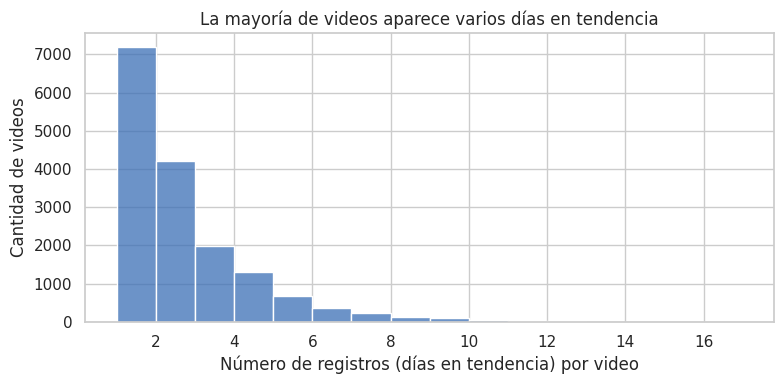

In [8]:
# Identificadores corruptos (p. ej. '#NAME?' o '#VALUE!', errores típicos de Excel): no identifican un video real
id_invalido = ~df["video_id"].str.fullmatch(r"[\w-]{11}")
print("video_id corruptos:", df.loc[id_invalido,"video_id"].value_counts().to_dict())
print("  -> 'video_id' más repetido en todo el archivo (incluye '#NAME?'):", df["video_id"].value_counts().iloc[0], "registros")

apar = df.loc[~id_invalido].groupby("video_id").size()
print(f"\nSolo con video_id válido -> Registros: {(~id_invalido).sum():,} | Videos únicos: {apar.size:,} | Promedio de registros por video: {apar.mean():.2f}")
print(f"Videos que aparecen en más de una fecha de tendencia: {(apar>1).sum():,} ({(apar>1).mean():.1%} de los videos)")
print(f"Máximo de apariciones de un mismo video (id válido): {apar.max()}")
display(apar.describe().to_frame("registros por video").T)

fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(apar, bins=range(1, int(apar.max())+2), color="#3b6fb6", ax=ax)
ax.set_title("La mayoría de videos aparece varios días en tendencia")
ax.set_xlabel("Número de registros (días en tendencia) por video"); ax.set_ylabel("Cantidad de videos")
plt.tight_layout(); plt.show()

**Lectura:** un mismo `video_id` se repite en distintas fechas, por lo que **contar filas ≠ contar videos**. En la Parte 4 se definirá explícitamente si cada indicador cuenta *registros*, *videos únicos* o *días de presencia*, y cómo se tratan las estadísticas acumuladas de videos observados varias veces.

### Diccionario de variables

In [9]:
diccionario = pd.DataFrame([
 ["video_id","Identificador único del video en YouTube (11 caracteres)","Texto"],
 ["trending_date","Fecha en que el video fue observado en la lista de tendencia (formato original aa.dd.mm)","Fecha"],
 ["title","Título del video","Texto"],
 ["channel_title","Nombre del canal que publicó el video","Texto"],
 ["category_id","Código numérico de la categoría del video; se relaciona con el JSON de categorías","Entero (categórica)"],
 ["publish_time","Fecha y hora (UTC) de publicación del video","Fecha-hora"],
 ["tags","Etiquetas del video separadas por '|'","Texto"],
 ["views","Número de vistas acumuladas del video al día del registro","Entero"],
 ["likes","Número de 'Me gusta' acumulados al día del registro","Entero"],
 ["dislikes","Número de 'No me gusta' acumulados al día del registro","Entero"],
 ["comment_count","Número de comentarios acumulados al día del registro","Entero"],
 ["thumbnail_link","URL de la miniatura del video","Texto"],
 ["comments_disabled","Indica si los comentarios están desactivados (VERDADERO/FALSO)","Lógico"],
 ["ratings_disabled","Indica si las valoraciones (me gusta / no me gusta) están desactivadas","Lógico"],
 ["video_error_or_removed","Indica si el video tiene error o fue retirado","Lógico"],
 ["description","Descripción del video (puede contener saltos de línea)","Texto"],
 ["state","Estado de la India asignado de forma aleatoria (simulado)","Texto (categórica)"],
 ["lat","Latitud del Estado asignado (simulada)","Decimal"],
 ["lon","Longitud del Estado asignado (simulada)","Decimal"],
 ["geometry","Geometría POINT (lon lat) del Estado asignado; opcional para GeoPandas (simulada)","Texto (WKT)"],
], columns=["Variable","Descripción","Tipo"])
diccionario["Tipo en pandas (tras lectura)"] = diccionario["Variable"].map(df.dtypes.astype(str))
diccionario["% nulos"] = diccionario["Variable"].map(df.isna().mean()*100).round(2)
diccionario

,Variable,Descripción,Tipo,Tipo en pandas (tras lectura),% nulos
0,video_id,Identificador único del video en YouTube (11 c...,Texto,object,0.00
1,trending_date,Fecha en que el video fue observado en la list...,Fecha,datetime64[ns],0.00
2,title,Título del video,Texto,object,0.00
3,channel_title,Nombre del canal que publicó el video,Texto,object,0.00
4,category_id,Código numérico de la categoría del video; se ...,Entero (categórica),Int64,0.00
5,publish_time,Fecha y hora (UTC) de publicación del video,Fecha-hora,"datetime64[ns, UTC]",0.00
6,tags,Etiquetas del video separadas por '|',Texto,object,0.00
7,views,Número de vistas acumuladas del video al día d...,Entero,int64,0.00
8,likes,Número de 'Me gusta' acumulados al día del reg...,Entero,int64,0.00
9,dislikes,Número de 'No me gusta' acumulados al día del ...,Entero,int64,0.00


### Relación entre el CSV y el JSON de categorías
El CSV guarda solo el **código** `category_id`; el JSON (`IN_category_id.json`) es el catálogo que traduce cada código (`items[].id`) a su nombre (`items[].snippet.title`). La relación es **muchos a uno**: muchos registros del CSV apuntan a una misma categoría del JSON.

In [10]:
with open(JSON_PATH, encoding="utf-8") as f:
    j = json.load(f)
cats = pd.DataFrame([{"category_id": int(it["id"]), "category": it["snippet"]["title"], "assignable": it["snippet"]["assignable"]} for it in j["items"]])
print(f"Categorías en el JSON: {len(cats)} | asignables: {cats.assignable.sum()}")

usadas = df["category_id"].dropna().astype(int).value_counts().rename_axis("category_id").reset_index(name="registros")
cruce = usadas.merge(cats, on="category_id", how="left")
print(f"Códigos distintos usados en el CSV: {len(usadas)} | sin correspondencia en el JSON: {cruce.category.isna().sum()}")
cruce

Categorías en el JSON: 31 | asignables: 14
Códigos distintos usados en el CSV: 17 | sin correspondencia en el JSON: 1


,category_id,registros,category,assignable
0,24,16712,Entertainment,True
1,25,5241,News & Politics,True
2,10,3858,Music,True
3,23,3429,Comedy,True
4,22,2624,People & Blogs,True
5,1,1658,Film & Animation,True
6,27,1227,Education,True
7,26,845,Howto & Style,True
8,17,731,Sports,True
9,28,552,Science & Technology,True


### Exploración inicial

,count,mean,std,min,25%,50%,75%,95%,99%,max
views,"37,352.00","1,060,477.65","3,184,932.05","4,024.00","123,915.50","304,586.00","799,291.25","4,190,777.10","13,305,944.98","125,432,237.00"
likes,"37,352.00","27,082.72","97,145.10",0.00,864.00,"3,069.00","13,774.25","124,652.45","432,675.00","2,912,710.00"
dislikes,"37,352.00","1,665.08","16,076.17",0.00,108.00,326.00,"1,019.25","5,629.00","21,373.36","1,545,017.00"
comment_count,"37,352.00","2,677.00","14,868.32",0.00,81.00,329.00,"1,285.00","9,986.00","42,380.28","827,755.00"


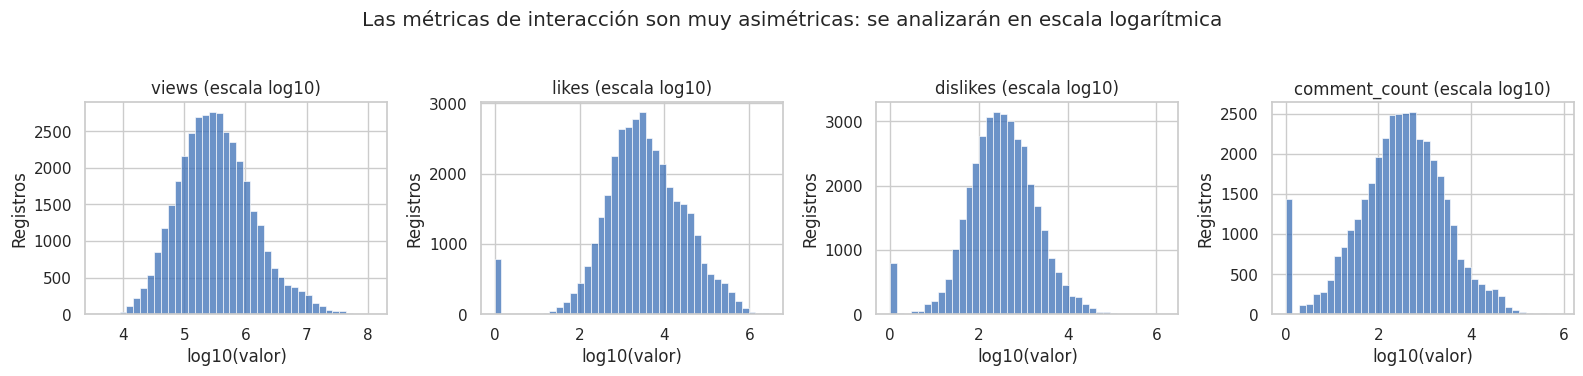

In [11]:
num = ["views","likes","dislikes","comment_count"]
display(df[num].describe(percentiles=[.25,.5,.75,.95,.99]).T)

fig, axes = plt.subplots(1, 4, figsize=(16,3.6))
for ax, c in zip(axes, num):
    sns.histplot(np.log10(df[c].clip(lower=1)), bins=40, color="#3b6fb6", ax=ax)
    ax.set_title(f"{c} (escala log10)"); ax.set_xlabel("log10(valor)"); ax.set_ylabel("Registros")
fig.suptitle("Las métricas de interacción son muy asimétricas: se analizarán en escala logarítmica", y=1.04)
plt.tight_layout(); plt.show()

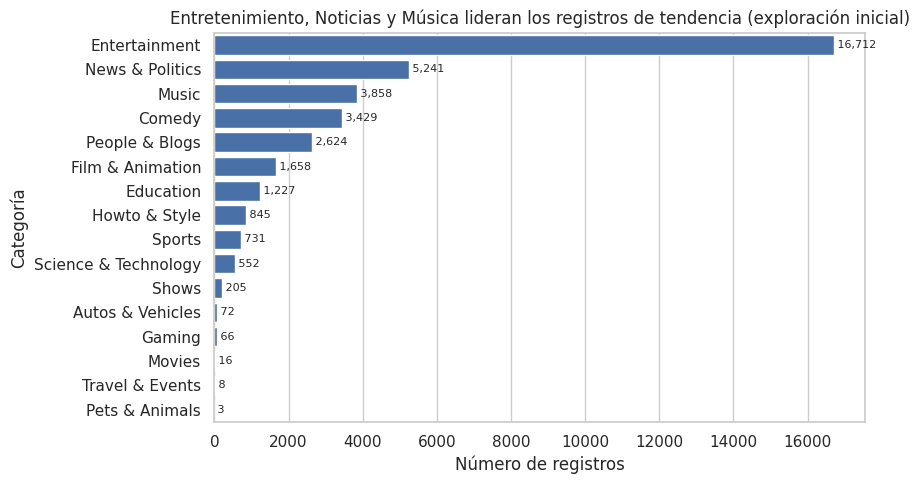

In [12]:
d = df.merge(cats[["category_id","category"]], on="category_id", how="left")
orden = d["category"].value_counts()
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x=orden.values, y=orden.index, color="#3b6fb6", ax=ax)
ax.set_title("Entretenimiento, Noticias y Música lideran los registros de tendencia (exploración inicial)")
ax.set_xlabel("Número de registros"); ax.set_ylabel("Categoría")
for i, v in enumerate(orden.values): ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

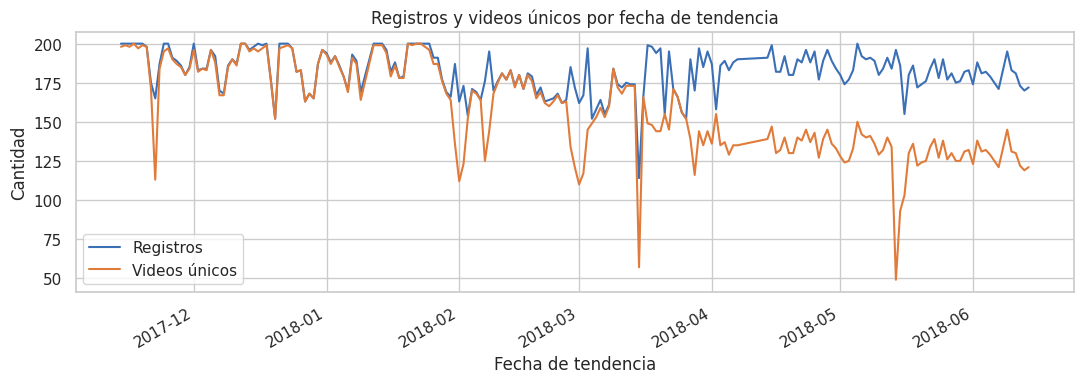

Registros por día: {'min': 114.0, '50%': 183.0, 'max': 200.0}


In [13]:
por_dia = df.groupby("trending_date").agg(registros=("video_id","size"), videos_unicos=("video_id","nunique"))
fig, ax = plt.subplots(figsize=(11,4))
por_dia.plot(ax=ax, color=["#3b6fb6","#e07b39"])
ax.set_title("Registros y videos únicos por fecha de tendencia")
ax.set_xlabel("Fecha de tendencia"); ax.set_ylabel("Cantidad"); ax.legend(["Registros","Videos únicos"])
plt.tight_layout(); plt.show()
print("Registros por día:", por_dia["registros"].describe()[["min","50%","max"]].to_dict())

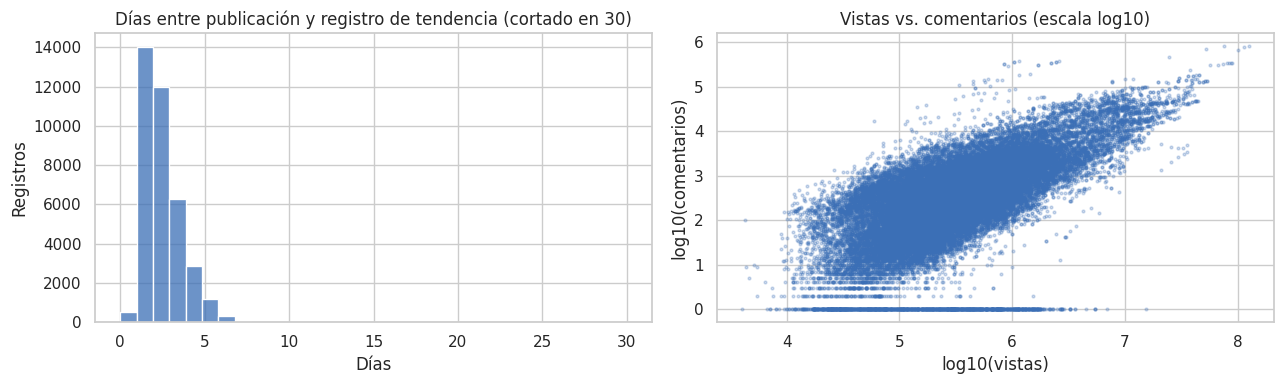

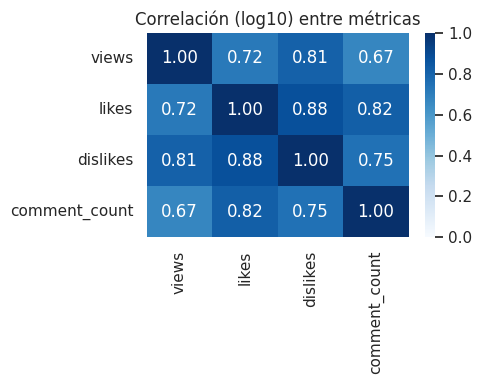

In [14]:
d["dias_a_tendencia"] = (d["trending_date"] - d["publish_time"].dt.tz_localize(None).dt.normalize()).dt.days
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(d["dias_a_tendencia"].clip(upper=30), bins=31, color="#3b6fb6", ax=axes[0])
axes[0].set_title("Días entre publicación y registro de tendencia (cortado en 30)")
axes[0].set_xlabel("Días"); axes[0].set_ylabel("Registros")

x = np.log10(d["views"].clip(lower=1)); y = np.log10(d["comment_count"].clip(lower=1))
axes[1].scatter(x, y, s=4, alpha=.25, color="#3b6fb6")
axes[1].set_title("Vistas vs. comentarios (escala log10)")
axes[1].set_xlabel("log10(vistas)"); axes[1].set_ylabel("log10(comentarios)")
plt.tight_layout(); plt.show()

corr = np.log10(df[num].clip(lower=1)).corr()
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Correlación (log10) entre métricas")
plt.tight_layout(); plt.show()

Estados distintos: 33 | mínimo 1,065 - máximo 1,190 registros por Estado (razón máx/mín = 1.12)


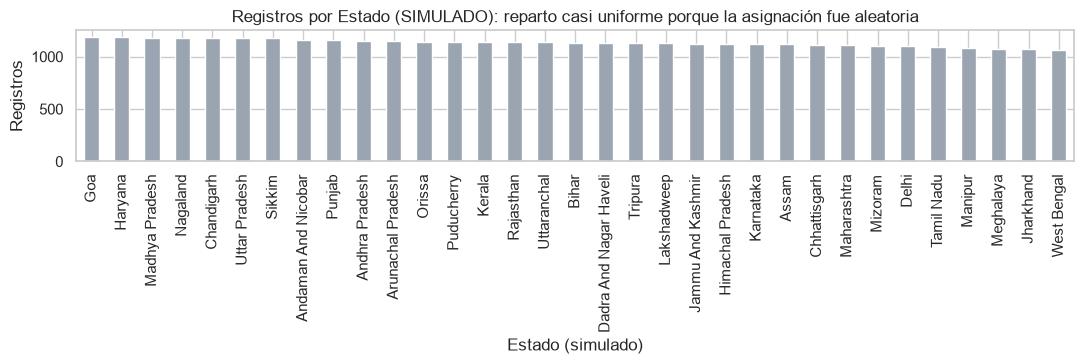

In [ ]:
# 'state' fue incorporado de forma aleatoria: se comprueba que su distribución es casi uniforme
est = df["state"].value_counts()
print(f"Estados distintos: {est.size} | mínimo {est.min():,} - máximo {est.max():,} registros por Estado (razón máx/mín = {est.max()/est.min():.2f})")
fig, ax = plt.subplots(figsize=(11,3.8))
est.plot.bar(color="#9aa5b1", ax=ax)
ax.set_title("Registros por Estado (SIMULADO): reparto casi uniforme porque la asignación fue aleatoria")
ax.set_xlabel("Estado (simulado)"); ax.set_ylabel("Registros")
plt.tight_layout(); plt.show()

**Lectura de la exploración inicial**
- Las vistas, me gusta, no me gusta y comentarios tienen **distribuciones muy sesgadas a la derecha**; pocos videos concentran valores extremos. Por eso se usará escala logarítmica y se evitará eliminar videos solo por tener muchas vistas (Parte 3.2).
- Vistas, me gusta y comentarios están **fuertemente relacionados** en escala log, lo que sugiere asociación (no causalidad) y obliga a cuidar la **fuga de información** al modelar vistas.
- El reparto por **Estado es casi uniforme**, coherente con una asignación aleatoria: **no tiene valor geográfico real**.
- La mayoría de videos entra a tendencia **pocos días después de publicarse**, y un mismo video permanece varios días.

### Diagnóstico de calidad y viabilidad
*(En esta parte solo se diagnostica; las decisiones de tratamiento y sus resultados se documentan en la Parte 3.)*

In [ ]:
fecha_pub = df["publish_time"].dt.tz_localize(None).dt.normalize()
checks = {}
checks["Filas fragmento (descripciones partidas, no son registros)"] = len(fragmentos)
checks["Registros exactamente duplicados (todas las columnas)"] = int(df.duplicated().sum())
checks["Duplicados por (video_id, trending_date)"] = int(df.duplicated(["video_id","trending_date"]).sum())
checks["video_id corrupto ('#NAME?' / '#VALUE!', error de Excel)"] = int(id_invalido.sum())
checks["Duplicados por (video_id, trending_date) con video_id válido"] = int(df.loc[~id_invalido].duplicated(["video_id","trending_date"]).sum())
checks["views = 0"] = int((df["views"]==0).sum())
checks["likes = 0"] = int((df["likes"]==0).sum())
checks["dislikes = 0"] = int((df["dislikes"]==0).sum())
checks["comment_count = 0"] = int((df["comment_count"]==0).sum())
checks["Valores negativos en métricas"] = int((df[num]<0).any(axis=1).sum())
checks["likes + dislikes > views"] = int(((df["likes"]+df["dislikes"])>df["views"]).sum())
checks["comment_count > views"] = int((df["comment_count"]>df["views"]).sum())
checks["comments_disabled = VERDADERO con comentarios > 0"] = int(((df["comments_disabled"]==True)&(df["comment_count"]>0)).sum())
checks["ratings_disabled = VERDADERO con likes/dislikes > 0"] = int(((df["ratings_disabled"]==True)&((df["likes"]>0)|(df["dislikes"]>0))).sum())
checks["comments_disabled = VERDADERO (comentarios no disponibles)"] = int((df["comments_disabled"]==True).sum())
checks["ratings_disabled = VERDADERO (valoraciones no disponibles)"] = int((df["ratings_disabled"]==True).sum())
checks["video_error_or_removed = VERDADERO"] = int((df["video_error_or_removed"]==True).sum())
checks["Publicación posterior a la fecha de tendencia"] = int((fecha_pub > df["trending_date"]).sum())
checks["category_id sin correspondencia en el JSON"] = int((~df["category_id"].isin(cats["category_id"])).sum())
checks["Categorías asignadas con assignable=false en el JSON"] = int(df["category_id"].isin(cats.loc[~cats.assignable,"category_id"]).sum())
checks["Videos con más de una categoría distinta"] = int((df.groupby("video_id")["category_id"].nunique()>1).sum())
checks["Descripción vacía"] = int(df["description"].isna().sum())
checks["Etiquetas vacías o '[none]'"] = int((df["tags"].isna() | (df["tags"]=="[none]")).sum())
diag = pd.Series(checks, name="Casos").to_frame()
diag["% de registros"] = (diag["Casos"]/len(df)*100).round(2)
diag

,Casos,% de registros
"Filas fragmento (descripciones partidas, no son registros)",1181,3.16
Registros exactamente duplicados (todas las columnas),120,0.32
"Duplicados por (video_id, trending_date)",4894,13.10
"video_id corrupto ('#NAME?' / '#VALUE!', error de Excel)",518,1.39
"Duplicados por (video_id, trending_date) con video_id válido",4569,12.23
views = 0,0,0.00
likes = 0,781,2.09
dislikes = 0,790,2.12
comment_count = 0,1322,3.54
Valores negativos en métricas,0,0.00


In [ ]:
print("Valores nulos por columna (sobre registros válidos):")
nulos = df.isna().sum(); display(nulos[nulos>0].to_frame("nulos").assign(pct=lambda x:(x.nulos/len(df)*100).round(2)))

# Cobertura temporal
rango = pd.date_range(f_min, f_max)
faltan = rango.difference(df["trending_date"].unique())
print(f"\nDías calendario en el rango: {len(rango)} | días con datos: {dias_obs} | días sin datos: {len(faltan)}")
if len(faltan): print("Primeros días sin datos:", [x.strftime('%Y-%m-%d') for x in faltan[:10]])

# Valores extremos pertinentes (se revisan en 3.2; aquí no se elimina nada)
print("\nTop 5 registros por vistas:")
display(d.nlargest(5,"views")[["title","channel_title","category","trending_date","views","likes","dislikes","comment_count"]].assign(title=lambda x:x.title.str.slice(0,50)))
print("Los Estados simulados coinciden con una única coordenada cada uno:", (df.groupby("state")[["lat","lon"]].nunique()==1).all().all())

Valores nulos por columna (sobre registros válidos):


,nulos,pct
description,561,1.50



Días calendario en el rango: 213 | días con datos: 205 | días sin datos: 8
Primeros días sin datos: ['2018-01-10', '2018-01-11', '2018-04-08', '2018-04-09', '2018-04-10', '2018-04-11', '2018-04-12', '2018-04-13']

Top 5 registros por vistas:


,title,channel_title,category,trending_date,views,likes,dislikes,comment_count
5408,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,Entertainment,2017-12-12,125432237,2912710,1545017,807558
5119,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,Entertainment,2017-12-11,113876217,2811216,1470387,787174
4936,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,Entertainment,2017-12-10,100911567,2656672,1353650,682890
4477,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,Entertainment,2017-12-07,89930713,2606663,53011,347982
4236,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,Entertainment,2017-12-06,87449453,2584674,52176,341571


Los Estados simulados coinciden con una única coordenada cada uno: True


### Síntesis de calidad y viabilidad

| Aspecto | Hallazgo | Implicancia |
|---|---|---|
| **Estructura del archivo** | Filas físicas ≠ registros: hay filas fragmento por descripciones con saltos de línea | Hay que depurarlas antes de cualquier conteo (Parte 3.1) |
| **Tipos y formatos** | Fecha de tendencia en formato `aa.dd.mm` (día antes que mes); métricas con enteros y decimales mezclados (`10` / `10.0`); lógicos en español (FALSO/VERDADERO) | Conversión explícita y validación de fechas |
| **Identificadores corruptos** | 518 registros con `video_id` = `#NAME?` (511) o `#VALUE!` (7), error típico de Excel: videos distintos comparten un mismo id | No se pueden contar como un video; inflan apariciones y duplicados (Parte 3) |
| **Duplicados** | 120 registros exactamente duplicados y 4.569 (≈12 %) repetidos por (`video_id`, `trending_date`) con id válido: el mismo video aparece más de una vez el mismo día | Definir regla de deduplicación y su efecto (Parte 3) |
| **Categorías** | El código 29 (105 registros) no existe en el JSON; las categorías 43 y 30 figuran como `assignable=false`; 26 videos cambian de categoría | Decidir cómo etiquetar/tratar categorías sin nombre (Parte 3) |
| **Unidad de análisis** | Un video aparece varias veces con valores acumulados | Distinguir registros, videos únicos y días de presencia (Parte 4.1) |
| **Ceros y faltantes** | Ceros en likes/dislikes/comentarios y valoraciones/comentarios desactivados | Regla explícita para razones y cocientes con denominador cero (R3, R4) |
| **Valores extremos** | Pocos videos con vistas muy altas | Revisión caso a caso; no se eliminan automáticamente (3.2) |
| **Geografía** | `state`, `lat`, `lon`, `geometry` fueron asignados al azar | No se usan para conclusiones reales ni como predictor |
| **Cobertura** | Solo India, periodo observado y videos que llegaron a tendencia | No extrapolar a todos los videos, usuarios o países |

**Viabilidad:** los datos permiten responder R1–R6, R8 y R9, y plantear el problema de regresión de `views`. R7 se responderá solo como simulación, porque los Estados no son reales.

---
# Parte 3. Preparación de los datos

**Propósito:** construir una base preparada para responder los requerimientos y dejar documentadas (bitácora) las decisiones que afectan la calidad y la interpretación de los resultados.

> Los archivos originales **no se modifican**: se calcula su huella (SHA-256) antes y después de la preparación para demostrarlo. La base preparada se guarda como un archivo nuevo.

## 3.1. Limpieza e integración

In [ ]:
import hashlib

def sha256(path, bloque=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(bloque):
            h.update(chunk)
    return h.hexdigest()

HASH_ANTES = {p.name: sha256(p) for p in (CSV_PATH, JSON_PATH)}
for k, v in HASH_ANTES.items():
    print(f"{k:28s} SHA-256 = {v[:16]}…")

# Bitácora de decisiones (se completa a medida que se trata cada problema)
bitacora = []
def registrar(problema, decision, justificacion, efecto):
    bitacora.append({"Problema": problema, "Decisión": decision, "Justificación": justificacion, "Efecto (registros / variables afectados)": efecto})

DIM_CRUDA = raw.shape
print("\nDimensiones del archivo crudo:", DIM_CRUDA)

INvideos_cc50_202101.csv     SHA-256 = cf6185b2200ad4e6…
IN_category_id.json          SHA-256 = f857cd2b580ebe12…

Dimensiones del archivo crudo: (38533, 20)


**Decisión 1 – Filas fragmento.** Se conservan solo las filas con fecha de tendencia válida (formato `aa.dd.mm`) e identificador presente; las demás son restos de descripciones partidas (ver 2.2). Estas filas implican además que la descripción del registro anterior quedó **cortada** (339 registros; media de 304 caracteres frente a 909 en el resto), lo que subestima `len_descripcion` en cerca del 1 % de los registros; se declara como limitación del modelo.

**Decisión 2 – Tipos de datos.** Se convierten a su tipo correcto las métricas (entero), las fechas, las variables lógicas (FALSO/VERDADERO → `bool`) y `category_id` (entero, pues aparecía como `10` y `10.0`). Ya se aplicó al crear `df` en la sección 2.2; aquí se deja constancia y se verifica.

In [ ]:
df0 = df.copy()   # registros válidos con tipos corregidos (viene de 2.2)

registrar("Filas 'fragmento' (restos de descripciones con saltos de línea)",
          "Excluir las filas sin fecha de tendencia válida ni video_id",
          "No son registros de tendencia: no tienen métricas y sus campos contienen texto de descripciones",
          f"{len(fragmentos):,} filas excluidas ({len(fragmentos)/len(raw):.1%} del archivo crudo)")

registrar("Tipos inadecuados (todo leído como texto; enteros como '10' y '10.0'; lógicos en español; fecha aa.dd.mm)",
          "Convertir a int64 / Int64 / bool / datetime (fecha con formato '%y.%d.%m', publicación en UTC)",
          "Permite calcular, ordenar y restar fechas sin errores; el día va antes que el mes en el formato original",
          "11 variables convertidas (views, likes, dislikes, comment_count, category_id, 3 lógicas, 2 fechas); 0 valores no convertibles")

assert df0["trending_date"].notna().all() and df0["publish_time"].notna().all()
print("Registros válidos:", len(df0), "| columnas:", df0.shape[1])
print(df0[["views","likes","dislikes","comment_count","category_id"]].dtypes.to_string())

Registros válidos: 37352 | columnas: 20
views            int64
likes            int64
dislikes         int64
comment_count    int64
category_id      Int64


**Decisión 3 – Identificadores corruptos (`#NAME?`, `#VALUE!`).** Son registros reales (tienen métricas coherentes) pero su `video_id` está dañado y **varios videos distintos comparten el mismo id**. En lugar de descartarlos, se crea una **clave de video** (`video_key`): el `video_id` cuando es válido y, cuando está corrupto, la combinación *título | canal | fecha de publicación*, que identifica al video de forma casi única.

In [ ]:
df1 = df0.copy()
id_malo = ~df1["video_id"].str.fullmatch(r"[\w-]{11}")
df1["video_key"] = np.where(
    id_malo,
    df1["title"] + " | " + df1["channel_title"] + " | " + df1["publish_time"].astype(str),
    df1["video_id"])

n_claves_nuevas = df1.loc[id_malo, "video_key"].nunique()
print(f"Registros con video_id corrupto: {id_malo.sum()} -> reconstruidos como {n_claves_nuevas} videos distintos (antes parecían 2)")
print("Videos únicos antes (por video_id):", df1["video_id"].nunique(), "| después (por video_key):", df1["video_key"].nunique())

registrar("video_id corrupto ('#NAME?' y '#VALUE!', error de Excel)",
          "Conservar el registro y construir video_key = título | canal | fecha de publicación cuando el id es inválido",
          "Evita perder registros reales y evita que videos distintos se cuenten como uno solo",
          f"{id_malo.sum()} registros; {n_claves_nuevas} videos reconstruidos; 1 variable nueva (video_key)")

Registros con video_id corrupto: 518 -> reconstruidos como 216 videos distintos (antes parecían 2)
Videos únicos antes (por video_id): 16307 | después (por video_key): 16521


**Decisión 4 – Duplicados exactos.** Registros idénticos en todas las columnas se eliminan: no aportan información.

**Decisión 5 – Duplicados por video y día.** Se revisa primero qué los distingue.

In [ ]:
n_exactos = int(df1.duplicated().sum())
df1 = df1.drop_duplicates().copy()
registrar("Registros exactamente duplicados", "Eliminar copias idénticas (se conserva una)",
          "Duplican el mismo video-día sin aportar información", f"{n_exactos} registros eliminados")

# ¿Qué distingue a los duplicados por (video_key, trending_date)?
dup = df1[df1.duplicated(["video_key","trending_date"], keep=False)].sort_values(["video_key","trending_date"])
grp = dup.groupby(["video_key","trending_date"])
resumen_dup = pd.DataFrame({
    "pares video-día duplicados": [grp.ngroups],
    "filas implicadas": [len(dup)],
    "% pares con views idénticas": [(grp["views"].nunique() == 1).mean() * 100],
    "% pares con state distinto": [(grp["state"].nunique() > 1).mean() * 100],
})
display(resumen_dup.round(1))
print("Ejemplo de un par duplicado:")
ej = dup.iloc[:2][["video_key","trending_date","views","likes","comment_count","state"]]
ej["video_key"] = ej["video_key"].str.slice(0, 40)
display(ej)

,pares video-día duplicados,filas implicadas,% pares con views idénticas,% pares con state distinto
0,4435,8961,98.30,99.70


Ejemplo de un par duplicado:


,video_key,trending_date,views,likes,comment_count,state
38191,#DeepthiSunaina Cheema joke chepthe navv,2018-06-13,675923,4642,920,Kerala
38314,#DeepthiSunaina Cheema joke chepthe navv,2018-06-13,675923,4642,920,Maharashtra


In [ ]:
antes = len(df1)
# Regla: un registro por video y día. Se conserva el de mayor número de vistas (estadística más reciente/completa).
df1 = (df1.sort_values(["video_key","trending_date","views"], ascending=[True, True, False])
          .drop_duplicates(["video_key","trending_date"], keep="first")
          .reset_index(drop=True))
n_dup_dia = antes - len(df1)
registrar("Mismo video repetido el mismo día (video_key + trending_date); difieren casi solo en 'state', que se asignó al azar por fila",
          "Conservar un registro por video y día (el de mayor 'views')",
          "El enunciado define la fila como video en un día de tendencia; las copias inflan conteos y sumas acumuladas",
          f"{n_dup_dia:,} registros eliminados ({n_dup_dia/antes:.1%})")
print(f"Registros: {antes:,} -> {len(df1):,} | ¿Aún hay pares duplicados? {df1.duplicated(['video_key','trending_date']).any()}")

Registros: 37,232 -> 32,706 | ¿Aún hay pares duplicados? False


**Decisión 6 – Integración con las categorías.** Se une el JSON mediante `category_id` ↔ `items[].id`. El código **29** no existe en el JSON: se conserva con una etiqueta explícita en lugar de imputarle un nombre. Se agrega además una traducción al español para los gráficos. Las categorías 30 y 43 sí existen en el JSON aunque figuren como `assignable = false`; se conservan.

In [ ]:
TRAD = {"Film & Animation":"Cine y animación","Autos & Vehicles":"Autos y vehículos","Music":"Música","Pets & Animals":"Mascotas y animales",
        "Sports":"Deportes","Travel & Events":"Viajes y eventos","Gaming":"Videojuegos","People & Blogs":"Personas y blogs","Comedy":"Comedia",
        "Entertainment":"Entretenimiento","News & Politics":"Noticias y política","Howto & Style":"Estilo y tutoriales","Education":"Educación",
        "Science & Technology":"Ciencia y tecnología","Movies":"Películas","Shows":"Programas"}

cat_en = cats.set_index("category_id")["category"]
df1["categoria_json"] = df1["category_id"].map(cat_en)
sin_json = df1["categoria_json"].isna()
df1["categoria"] = df1["categoria_json"].map(TRAD)
df1.loc[sin_json, "categoria"] = "Sin nombre en JSON (id " + df1.loc[sin_json, "category_id"].astype(str) + ")"

print("Registros sin correspondencia en el JSON:", int(sin_json.sum()), "->", df1.loc[sin_json, "categoria"].unique().tolist())
assert df1["categoria"].notna().all() and df1["category_id"].notna().all()
print("Videos que cambian de categoría entre registros:", int((df1.groupby('video_key')['category_id'].nunique() > 1).sum()))
registrar("category_id 29 sin correspondencia en el JSON (y 26 videos con más de una categoría)",
          "Conservar los registros con la etiqueta 'Sin nombre en JSON (id 29)'; añadir categoria (español) y categoria_json (original); para análisis por video se usa la categoría de su primer registro",
          "Inventar un nombre sería una suposición no respaldada por los archivos; perderlos sesgaría la presencia de categorías",
          f"{int(sin_json.sum())} registros etiquetados; 2 variables nuevas (categoria, categoria_json)")

Registros sin correspondencia en el JSON: 103 -> ['Sin nombre en JSON (id 29)']
Videos que cambian de categoría entre registros: 26


**Decisión 7 – Interacciones no disponibles.** Cuando `comments_disabled = VERDADERO` el comentario cuenta 0, y cuando `ratings_disabled = VERDADERO` los me gusta y no me gusta cuentan 0: **ese cero significa "no disponible", no "ninguna interacción"**. Se verifica y se define que los indicadores de razón (R3, R4) los excluyan. Las columnas originales no se modifican.

In [ ]:
print("Con comentarios desactivados -> comment_count distinto de 0:", int(((df1.comments_disabled) & (df1.comment_count != 0)).sum()))
print("Con valoraciones desactivadas -> likes o dislikes distintos de 0:", int(((df1.ratings_disabled) & ((df1.likes != 0) | (df1.dislikes != 0))).sum()))
print("Ceros 'genuinos' (función activa): comment_count=0:", int(((~df1.comments_disabled) & (df1.comment_count == 0)).sum()),
      "| likes=0:", int(((~df1.ratings_disabled) & (df1.likes == 0)).sum()),
      "| dislikes=0:", int(((~df1.ratings_disabled) & (df1.dislikes == 0)).sum()))

registrar("Ceros que significan 'no disponible' (comentarios o valoraciones desactivados)",
          "Mantener las columnas originales; en los indicadores de razón (R3, R4) usar NaN y excluir esos registros/videos",
          "Un cero por desactivación no es 'cero interacción'; incluirlo subestimaría la participación de la audiencia",
          f"{int(df1.comments_disabled.sum())} registros sin comentarios disponibles; {int(df1.ratings_disabled.sum())} sin valoraciones disponibles")

Con comentarios desactivados -> comment_count distinto de 0: 0
Con valoraciones desactivadas -> likes o dislikes distintos de 0: 0
Ceros 'genuinos' (función activa): comment_count=0: 116 | likes=0: 0 | dislikes=0: 9


In [ ]:
# Decisión 8 – etiquetas/descripciones vacías y videos con error o retirados
n_tags_none = int((df1["tags"] == "[none]").sum())
n_desc_nan = int(df1["description"].isna().sum())
n_error = int(df1["video_error_or_removed"].sum())
print("tags = '[none]':", n_tags_none, "| description vacía:", n_desc_nan, "| video_error_or_removed = VERDADERO:", n_error)
display(df1.loc[df1.video_error_or_removed, ["title","channel_title","views","likes","comment_count"]].assign(title=lambda x: x.title.str.slice(0, 45)).head(6))

registrar("Etiquetas '[none]' y descripciones vacías",
          "No imputar; n_tags = 0 y len_descripcion = 0 en las variables derivadas",
          "La ausencia de etiquetas/descripción es información válida (el creador no las completó)",
          f"{n_tags_none} registros con tags '[none]'; {n_desc_nan} con descripción vacía")
registrar("video_error_or_removed = VERDADERO",
          "Conservar los registros (tienen métricas coherentes) y mantener la bandera",
          "Son pocos, sus estadísticas son válidas y su exclusión no cambia los resultados; se evita eliminar sin evidencia de error",
          f"{n_error} registros marcados")
registrar("Variables geográficas simuladas (state, lat, lon, geometry)",
          "Conservarlas solo para el ejercicio R7 (rotulado SIMULACIÓN); excluirlas del modelo y de conclusiones comerciales",
          "Fueron asignadas al azar; no representan ubicación real de los videos",
          "4 variables apartadas del análisis de negocio y del modelado")

tags = '[none]': 1265 | description vacía: 527 | video_error_or_removed = VERDADERO: 6


,title,channel_title,views,likes,comment_count
27660,Earth Day 2018 Google Doodle,googledoodles,2919347,344509,29131
27661,Earth Day 2018 Google Doodle,googledoodles,4733057,445944,35394
27662,Earth Day 2018 Google Doodle,googledoodles,1682462,175181,14250
27663,Earth Day 2018 Google Doodle,googledoodles,880003,14642,2875
27664,Earth Day 2018 Google Doodle,googledoodles,521421,34559,5723
27665,Earth Day 2018 Google Doodle,googledoodles,349858,40377,4982


## 3.2. Valores atípicos

Se identifican valores extremos con el criterio del rango intercuartílico (IQR) sobre la escala logarítmica, apropiada para variables muy asimétricas. **No se elimina ningún video solo por tener muchas vistas, interacciones o comentarios**: primero se revisa si son errores, observaciones plausibles o casos a revisar.

,mediana,"límite superior (IQR, escala original)",atípicos altos,% altos,atípicos bajos,máximo
variable,,,,,,
views,"270,668","11,532,201",357,1.09,9,"125,432,237"
likes,"2,690","654,505",110,0.34,727,"2,912,710"
dislikes,283,"26,050",198,0.61,775,"1,545,017"
comment_count,290,"72,483",104,0.32,1327,"827,755"


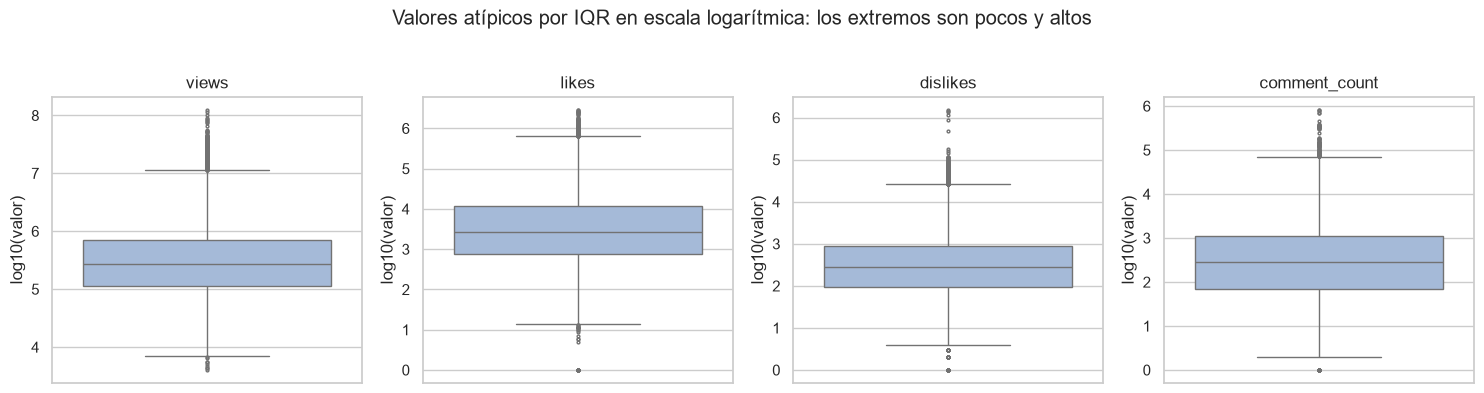

In [ ]:
def fences(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

filas = []
for c in ["views", "likes", "dislikes", "comment_count"]:
    s = np.log10(df1[c].clip(lower=1))
    lo, hi = fences(s)
    n_hi = int((s > hi).sum()); n_lo = int((s < lo).sum())
    filas.append({"variable": c, "mediana": df1[c].median(), "límite superior (IQR, escala original)": 10 ** hi,
                  "atípicos altos": n_hi, "% altos": n_hi / len(df1) * 100, "atípicos bajos": n_lo, "máximo": df1[c].max()})
tabla_atipicos = pd.DataFrame(filas).set_index("variable")
display(tabla_atipicos.style.format({"mediana": "{:,.0f}", "límite superior (IQR, escala original)": "{:,.0f}", "% altos": "{:.2f}", "máximo": "{:,.0f}"}))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, c in zip(axes, ["views", "likes", "dislikes", "comment_count"]):
    sns.boxplot(y=np.log10(df1[c].clip(lower=1)), color="#9db8e0", fliersize=2, ax=ax)
    ax.set_title(f"{c}"); ax.set_ylabel("log10(valor)")
fig.suptitle("Valores atípicos por IQR en escala logarítmica (los valores bajos corresponden sobre todo a ceros)", y=1.03)
plt.tight_layout(); plt.show()

**Cómo leer la tabla.** En `views` los atípicos son casi todos altos (357 altos y 9 bajos). En `likes`, `dislikes` y `comment_count` hay más atípicos bajos que altos (por ejemplo, 1.327 bajos frente a 104 altos en comentarios). Esos bajos **no son videos poco vistos**: son sobre todo ceros que, al acotar en 1 antes del logaritmo, caen bajo el límite inferior. Corresponden a funciones desactivadas (1.103 registros sin comentarios y 710 sin valoraciones, Decisión 7) y a ceros genuinos (116 en comentarios). Por eso solo se marcan los atípicos altos de `views` (`atipico_views`) y no se trata ningún atípico bajo.

In [ ]:
# Revisión caso por caso de los extremos más altos (nivel video, máximos observados)
top = (df1.groupby("video_key").agg(titulo=("title", "first"), canal=("channel_title", "first"), vistas_max=("views", "max"),
                                     likes_max=("likes", "max"), dislikes_max=("dislikes", "max"), comentarios_max=("comment_count", "max"),
                                     dias_en_tendencia=("trending_date", "size"))
         .nlargest(8, "vistas_max").reset_index(drop=True))
top["titulo"] = top["titulo"].str.slice(0, 55)
display(top.style.format({"vistas_max": "{:,.0f}", "likes_max": "{:,.0f}", "dislikes_max": "{:,.0f}", "comentarios_max": "{:,.0f}"}))

# Pruebas de imposibilidad (si fueran errores, aparecerían aquí)
print("likes + dislikes > views     :", int(((df1.likes + df1.dislikes) > df1.views).sum()))
print("comment_count > views        :", int((df1.comment_count > df1.views).sum()))
print("views <= 0 o negativos        :", int((df1.views <= 0).sum()))

# Marca (no eliminación) y efecto sobre los estadísticos
lo, hi = fences(np.log10(df1["views"]))
df1["atipico_views"] = np.log10(df1["views"]) > hi
sin = df1.loc[~df1.atipico_views, "views"]
efecto = pd.DataFrame({"con todos los registros": [df1.views.mean(), df1.views.median(), df1.views.std()],
                       "sin los marcados": [sin.mean(), sin.median(), sin.std()]}, index=["media", "mediana", "desv. estándar"])
print(f"\nRegistros marcados como atípicos en views: {int(df1.atipico_views.sum())} ({df1.atipico_views.mean():.2%})")
display(efecto.style.format("{:,.0f}"))

,titulo,canal,vistas_max,likes_max,dislikes_max,comentarios_max,dias_en_tendencia
0,YouTube Rewind: The Shape of 2017 | #YouTubeRewind,YouTube Spotlight,"125,432,237","2,912,710","1,545,017","827,755",6
1,Marvel Studios' Avengers: Infinity War Official Trailer,Marvel Entertainment,"89,930,713","2,606,663","53,011","347,982",8
2,VENOM - Official Trailer (HD),Sony Pictures Entertainment,"53,822,757","1,250,535","44,796","135,405",7
3,Marvel Studios' Avengers: Infinity War - Official Trail,Marvel Entertainment,"45,064,699","1,494,997","29,812","186,005",6
4,Sanju | Official Teaser | Ranbir Kapoor | Rajkumar Hira,FoxStarHindi,"44,171,797","780,895","30,791","47,829",9
5,Taylor Swift - Delicate,TaylorSwiftVEVO,"43,738,208","1,658,756","94,043","148,548",6
6,"Taylor Swift - End Game ft. Ed Sheeran, Future",TaylorSwiftVEVO,"42,019,590","1,804,377","100,033","146,917",6
7,Swag Se Swagat Song | Tiger Zinda Hai | Salman Khan | K,YRF,"40,953,758","679,940","69,161","65,564",5


likes + dislikes > views     : 0
comment_count > views        : 0
views <= 0 o negativos        : 0

Registros marcados como atípicos en views: 357 (1.09%)


,con todos los registros,sin los marcados
media,"961,744","723,963"
mediana,"270,668","265,454"
desv. estándar,"3,075,813","1,377,768"


**Decisión sobre atípicos:** los valores extremos son **plausibles** (videos de gran alcance como los de mayor audiencia del periodo; ninguno incumple las reglas lógicas) y representan justamente el contenido que interesa a la empresa de marketing. **No se eliminan**: se marcan con `atipico_views` y se controlan con la **escala logarítmica** (media y desviación son sensibles; la mediana apenas cambia, ver tabla). En el modelado se evalúa además su efecto (Parte 5).

In [ ]:
registrar("Valores extremos altos en views/likes/dislikes/comentarios (IQR en escala log)",
          "No eliminar; marcar con atipico_views y trabajar en escala logarítmica / con medianas en los casos sensibles",
          "Son plausibles (videos muy virales, ninguno viola reglas lógicas) y son el objeto de interés del cliente",
          f"{int(df1.atipico_views.sum())} registros marcados; 1 variable nueva (atipico_views); 0 registros eliminados")

## 3.3. Construcción de variables

Se construyen las variables necesarias para los requerimientos y para el modelo. La hora de publicación se expresa en **hora de la India (IST = UTC+5:30)**, que es la relevante para la audiencia analizada.

In [ ]:
df1 = df1.sort_values(["video_key", "trending_date"]).reset_index(drop=True)

# --- tiempo ---
pub_naive_utc = df1["publish_time"].dt.tz_localize(None)
df1["dias_a_tendencia"] = (df1["trending_date"] - pub_naive_utc.dt.normalize()).dt.days
pub_ist = pub_naive_utc + pd.Timedelta(hours=5, minutes=30)
df1["hora_pub_ist"] = pub_ist.dt.hour
df1["dia_semana_pub"] = pub_ist.dt.dayofweek.map({0:"Lunes",1:"Martes",2:"Miércoles",3:"Jueves",4:"Viernes",5:"Sábado",6:"Domingo"})
df1["franja_pub"] = pd.cut(df1["hora_pub_ist"], bins=[-1, 5, 11, 17, 23], labels=["Madrugada (0-5h)", "Mañana (6-11h)", "Tarde (12-17h)", "Noche (18-23h)"]).astype(str)

# --- texto ---
df1["len_titulo"] = df1["title"].str.len()
df1["n_tags"] = np.where(df1["tags"].isin(["[none]"]) | df1["tags"].isna(), 0, df1["tags"].str.count(r"\|") + 1)
df1["len_descripcion"] = df1["description"].fillna("").str.len()

# --- interacción (NaN cuando no disponible o denominador 0) ---
vistas = df1["views"].astype(float)
ok_val = ~df1["ratings_disabled"]
ok_com = ~df1["comments_disabled"]
df1["prop_likes"] = np.where(ok_val & ((df1.likes + df1.dislikes) > 0), df1.likes / (df1.likes + df1.dislikes).replace(0, np.nan), np.nan)
df1["likes_por_mil_vistas"] = np.where(ok_val, df1.likes / vistas * 1000, np.nan)
df1["dislikes_por_mil_vistas"] = np.where(ok_val, df1.dislikes / vistas * 1000, np.nan)
df1["comentarios_por_mil_vistas"] = np.where(ok_com, df1.comment_count / vistas * 1000, np.nan)
df1["vistas_por_comentario"] = np.where(ok_com & (df1.comment_count > 0), vistas / df1.comment_count.replace(0, np.nan), np.nan)
df1["interaccion_por_mil_vistas"] = np.where(ok_val | ok_com, (df1.likes + df1.dislikes + df1.comment_count) / vistas * 1000, np.nan)

# --- escala y posición dentro de la vida del video ---
df1["log_views"] = np.log(df1["views"])
df1["orden_aparicion"] = df1.groupby("video_key").cumcount() + 1
df1["es_primer_registro"] = df1["orden_aparicion"] == 1
df1["dias_en_tendencia_video"] = df1.groupby("video_key")["trending_date"].transform("size")

derivadas = ["dias_a_tendencia","hora_pub_ist","dia_semana_pub","franja_pub","len_titulo","n_tags","len_descripcion","prop_likes",
             "likes_por_mil_vistas","dislikes_por_mil_vistas","comentarios_por_mil_vistas","vistas_por_comentario","interaccion_por_mil_vistas",
             "log_views","orden_aparicion","es_primer_registro","dias_en_tendencia_video"]
print("Variables derivadas creadas:", len(derivadas))

Variables derivadas creadas: 17


In [ ]:
dic_deriv = pd.DataFrame([
 ["dias_a_tendencia", "Días entre la fecha de publicación (UTC) y la fecha del registro de tendencia", "trending_date − fecha(publish_time)", "días", "Modelo; R9", "Negativo sería imposible (se verifica: 0 casos)"],
 ["hora_pub_ist", "Hora de publicación en hora de la India", "hora(publish_time + 5 h 30 min)", "hora (0–23)", "Modelo", "—"],
 ["dia_semana_pub", "Día de la semana de publicación (IST)", "día de la semana de (publish_time + 5 h 30 min)", "categórica", "Modelo", "—"],
 ["franja_pub", "Franja horaria de publicación", "Madrugada 0-5 h, mañana 6-11 h, tarde 12-17 h, noche 18-23 h", "categórica", "Modelo", "—"],
 ["len_titulo", "Longitud del título", "número de caracteres de title", "caracteres", "Modelo", "—"],
 ["n_tags", "Cantidad de etiquetas", "conteo de '|' + 1", "etiquetas", "Modelo", "0 si tags = '[none]' o vacío"],
 ["len_descripcion", "Longitud de la descripción", "número de caracteres de description", "caracteres", "Modelo", "0 si la descripción está vacía"],
 ["prop_likes", "Proporción de 'me gusta' sobre las valoraciones", "likes / (likes + dislikes)", "proporción 0–1", "R3", "NaN si valoraciones desactivadas o likes + dislikes = 0"],
 ["likes_por_mil_vistas", "Me gusta por cada 1.000 vistas", "likes / views × 1000", "por 1.000 vistas", "Exploración", "NaN si valoraciones desactivadas"],
 ["dislikes_por_mil_vistas", "No me gusta por cada 1.000 vistas", "dislikes / views × 1000", "por 1.000 vistas", "Exploración", "NaN si valoraciones desactivadas"],
 ["comentarios_por_mil_vistas", "Comentarios por cada 1.000 vistas (más alto = más conversación)", "comment_count / views × 1000", "por 1.000 vistas", "R4", "NaN si comentarios desactivados (views > 0 siempre)"],
 ["vistas_por_comentario", "Vistas necesarias por cada comentario (más alto = menos conversación). Es el inverso del anterior ×1000", "views / comment_count", "vistas por comentario", "R4", "NaN si comentarios desactivados o comment_count = 0"],
 ["interaccion_por_mil_vistas", "Interacción total por cada 1.000 vistas", "(likes + dislikes + comment_count) / views × 1000", "por 1.000 vistas", "Exploración", "NaN si comentarios y valoraciones están ambos desactivados"],
 ["log_views", "Logaritmo natural de las vistas", "ln(views)", "log(vistas)", "Variable objetivo (Parte 5)", "views ≥ 4.024: sin ceros"],
 ["orden_aparicion", "N.º de aparición del video en la lista (1 = primera vez)", "posición del registro dentro de su video_key, por fecha", "entero", "Unidad de análisis; modelo", "—"],
 ["es_primer_registro", "Indica el primer registro de tendencia del video", "orden_aparicion == 1", "lógico", "Modelo", "—"],
 ["dias_en_tendencia_video", "Registros (días) que el video acumula en tendencia", "conteo de registros por video_key", "días", "R6, R9", "—"],
], columns=["Variable", "Definición", "Fórmula", "Unidad", "Uso", "Casos especiales"])
display(dic_deriv)

,Variable,Definición,Fórmula,Unidad,Uso,Casos especiales
0,dias_a_tendencia,Días entre la fecha de publicación (UTC) y la ...,trending_date − fecha(publish_time),días,Modelo; R9,Negativo sería imposible (se verifica: 0 casos)
1,hora_pub_ist,Hora de publicación en hora de la India,hora(publish_time + 5 h 30 min),hora (0–23),Modelo,—
2,dia_semana_pub,Día de la semana de publicación (IST),día de la semana de (publish_time + 5 h 30 min),categórica,Modelo,—
3,franja_pub,Franja horaria de publicación,"Madrugada 0-5 h, mañana 6-11 h, tarde 12-17 h,...",categórica,Modelo,—
4,len_titulo,Longitud del título,número de caracteres de title,caracteres,Modelo,—
5,n_tags,Cantidad de etiquetas,conteo de '|' + 1,etiquetas,Modelo,0 si tags = '[none]' o vacío
6,len_descripcion,Longitud de la descripción,número de caracteres de description,caracteres,Modelo,0 si la descripción está vacía
7,prop_likes,Proporción de 'me gusta' sobre las valoraciones,likes / (likes + dislikes),proporción 0–1,R3,NaN si valoraciones desactivadas o likes + dis...
8,likes_por_mil_vistas,Me gusta por cada 1.000 vistas,likes / views × 1000,por 1.000 vistas,Exploración,NaN si valoraciones desactivadas
9,dislikes_por_mil_vistas,No me gusta por cada 1.000 vistas,dislikes / views × 1000,por 1.000 vistas,Exploración,NaN si valoraciones desactivadas


In [ ]:
# Verificación de resultados imposibles y denominadores iguales a cero
ver = pd.DataFrame({
  "NaN": df1[derivadas].isna().sum(),
  "inf": df1[derivadas].select_dtypes("number").apply(lambda s: np.isinf(s).sum()).reindex(derivadas).fillna(0).astype(int),
}).T
display(ver)
print("dias_a_tendencia < 0                          :", int((df1.dias_a_tendencia < 0).sum()))
print("prop_likes fuera de [0, 1]                    :", int(((df1.prop_likes < 0) | (df1.prop_likes > 1)).sum()))
print("Denominador 0 -> likes+dislikes = 0 con valoraciones activas:", int(((df1.likes + df1.dislikes == 0) & ~df1.ratings_disabled).sum()), "(prop_likes = NaN)")
print("Denominador 0 -> comment_count = 0 con comentarios activos  :", int(((df1.comment_count == 0) & ~df1.comments_disabled).sum()), "(vistas_por_comentario = NaN)")
print("views = 0 (denominador de las tasas por mil vistas)          :", int((df1.views == 0).sum()))
print("\nDistribución de dias_a_tendencia:")
display(df1.loc[df1.es_primer_registro, "dias_a_tendencia"].describe(percentiles=[.5, .9, .99]).round(1).to_frame().T)

registrar("Faltan variables de tiempo, texto e interacción para los requerimientos y el modelo",
          "Crear 17 variables derivadas (ver tabla de definiciones), con NaN explícito en casos no definidos",
          "Cada una tiene fórmula, unidad y regla para casos especiales; no se generan infinitos ni valores imposibles",
          f"17 variables nuevas; NaN en indicadores de razón: prop_likes={int(df1.prop_likes.isna().sum())}, comentarios_por_mil_vistas={int(df1.comentarios_por_mil_vistas.isna().sum())}")

,dias_a_tendencia,hora_pub_ist,dia_semana_pub,franja_pub,len_titulo,n_tags,len_descripcion,prop_likes,likes_por_mil_vistas,dislikes_por_mil_vistas,comentarios_por_mil_vistas,vistas_por_comentario,interaccion_por_mil_vistas,log_views,orden_aparicion,es_primer_registro,dias_en_tendencia_video
NaN,0,0,0,0,0,0,0,710,710,710,1103,1219,333,0,0,0,0
inf,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


dias_a_tendencia < 0                          : 0
prop_likes fuera de [0, 1]                    : 0
Denominador 0 -> likes+dislikes = 0 con valoraciones activas: 0 (prop_likes = NaN)
Denominador 0 -> comment_count = 0 con comentarios activos  : 116 (vistas_por_comentario = NaN)
views = 0 (denominador de las tasas por mil vistas)          : 0

Distribución de dias_a_tendencia:


,count,mean,std,min,50%,90%,99%,max
dias_a_tendencia,"16,521.00",1.30,1.90,0.00,1.00,2.00,3.00,220.00


## 3.4. Bitácora y validación final

In [ ]:
df_prep = df1.copy()

# Dimensiones antes / después
comp = pd.DataFrame({
  "Archivo crudo": [DIM_CRUDA[0], DIM_CRUDA[1], df0["video_id"].nunique()],
  "Base preparada": [df_prep.shape[0], df_prep.shape[1], df_prep["video_key"].nunique()]}, index=["Filas", "Columnas", "Videos únicos (por id)"])
display(comp)
print("Embudo de filas:", f"{DIM_CRUDA[0]:,} (crudo) -> {len(df0):,} (sin fragmentos) -> {len(df0)-n_exactos:,} (sin exactos) -> {len(df_prep):,} (un registro por video y día)")

# Validaciones finales de tipos, rangos y significado
assert df_prep.duplicated(["video_key", "trending_date"]).sum() == 0
assert df_prep[["views", "likes", "dislikes", "comment_count"]].ge(0).all().all()
assert (df_prep["views"] > 0).all()
assert df_prep["trending_date"].between("2017-11-14", "2018-06-14").all()
assert (df_prep["dias_a_tendencia"] >= 0).all()
assert df_prep["prop_likes"].dropna().between(0, 1).all()
assert df_prep["categoria"].notna().all()
assert df_prep["es_primer_registro"].sum() == df_prep["video_key"].nunique()
print("Todas las validaciones se cumplieron.")
display(df_prep[["views", "likes", "dislikes", "comment_count", "dias_a_tendencia", "len_titulo", "n_tags", "log_views"]].describe().T.round(2))

,Archivo crudo,Base preparada
Filas,38533,32706
Columnas,20,41
Videos únicos (por id),16535,16521


Embudo de filas: 38,533 (crudo) -> 37,352 (sin fragmentos) -> 37,232 (sin exactos) -> 32,706 (un registro por video y día)
Todas las validaciones se cumplieron.


,count,mean,std,min,25%,50%,75%,max
views,"32,706.00","961,744.31","3,075,812.84","4,024.00","111,598.50","270,668.00","713,444.00","125,432,237.00"
likes,"32,706.00","24,258.08","93,510.79",0.00,776.00,"2,690.00","11,489.00","2,912,710.00"
dislikes,"32,706.00","1,524.59","16,953.32",0.00,96.00,283.00,903.00,"1,545,017.00"
comment_count,"32,706.00","2,411.74","14,660.13",0.00,70.00,290.00,"1,125.00","827,755.00"
dias_a_tendencia,"32,706.00",2.11,2.16,0.00,1.00,2.00,3.00,221.00
len_titulo,"32,706.00",71.04,22.22,5.00,54.00,74.00,91.00,100.00
n_tags,"32,706.00",18.59,10.01,0.00,11.00,18.00,25.00,72.00
log_views,"32,706.00",12.60,1.40,8.30,11.62,12.51,13.48,18.65


**Nota sobre los videos únicos.** En el archivo crudo se cuentan los `video_id` de los **registros válidos** (16.307). Contar directamente la columna del archivo crudo daría 16.535, porque incluiría 228 textos de descripciones que las filas fragmento dejan en esa columna. En la base preparada se cuentan `video_key` (16.521): el aumento se debe a que los 518 registros con `video_id` corrupto, que antes parecían 2 videos, se reconstruyeron como 216.

In [ ]:
bit = pd.DataFrame(bitacora)
bit.index = range(1, len(bit) + 1)
pd.set_option("display.max_colwidth", 120)
display(bit)

,Problema,Decisión,Justificación,Efecto (registros / variables afectados)
1,Filas 'fragmento' (restos de descripciones con saltos de línea),Excluir las filas sin fecha de tendencia válida ni video_id,No son registros de tendencia: no tienen métricas y sus campos contienen texto de descripciones,"1,181 filas excluidas (3.1% del archivo crudo)"
2,Tipos inadecuados (todo leído como texto; enteros como '10' y '10.0'; lógicos en español; fecha aa.dd.mm),"Convertir a int64 / Int64 / bool / datetime (fecha con formato '%y.%d.%m', publicación en UTC)","Permite calcular, ordenar y restar fechas sin errores; el día va antes que el mes en el formato original","11 variables convertidas (views, likes, dislikes, comment_count, category_id, 3 lógicas, 2 fechas); 0 valores no con..."
3,"video_id corrupto ('#NAME?' y '#VALUE!', error de Excel)",Conservar el registro y construir video_key = título | canal | fecha de publicación cuando el id es inválido,Evita perder registros reales y evita que videos distintos se cuenten como uno solo,518 registros; 216 videos reconstruidos; 1 variable nueva (video_key)
4,Registros exactamente duplicados,Eliminar copias idénticas (se conserva una),Duplican el mismo video-día sin aportar información,120 registros eliminados
5,"Mismo video repetido el mismo día (video_key + trending_date); difieren casi solo en 'state', que se asignó al azar ...",Conservar un registro por video y día (el de mayor 'views'),El enunciado define la fila como video en un día de tendencia; las copias inflan conteos y sumas acumuladas,"4,526 registros eliminados (12.2%)"
6,category_id 29 sin correspondencia en el JSON (y 26 videos con más de una categoría),Conservar los registros con la etiqueta 'Sin nombre en JSON (id 29)'; añadir categoria (español) y categoria_json (o...,Inventar un nombre sería una suposición no respaldada por los archivos; perderlos sesgaría la presencia de categorías,"103 registros etiquetados; 2 variables nuevas (categoria, categoria_json)"
7,Ceros que significan 'no disponible' (comentarios o valoraciones desactivados),"Mantener las columnas originales; en los indicadores de razón (R3, R4) usar NaN y excluir esos registros/videos",Un cero por desactivación no es 'cero interacción'; incluirlo subestimaría la participación de la audiencia,1103 registros sin comentarios disponibles; 710 sin valoraciones disponibles
8,Etiquetas '[none]' y descripciones vacías,No imputar; n_tags = 0 y len_descripcion = 0 en las variables derivadas,La ausencia de etiquetas/descripción es información válida (el creador no las completó),1265 registros con tags '[none]'; 527 con descripción vacía
9,video_error_or_removed = VERDADERO,Conservar los registros (tienen métricas coherentes) y mantener la bandera,"Son pocos, sus estadísticas son válidas y su exclusión no cambia los resultados; se evita eliminar sin evidencia de ...",6 registros marcados
10,"Variables geográficas simuladas (state, lat, lon, geometry)",Conservarlas solo para el ejercicio R7 (rotulado SIMULACIÓN); excluirlas del modelo y de conclusiones comerciales,Fueron asignadas al azar; no representan ubicación real de los videos,4 variables apartadas del análisis de negocio y del modelado


In [ ]:
# Guardar la versión preparada (archivo nuevo) y comprobar que los originales no cambiaron
OUT_DIR = Path("data_preparada"); OUT_DIR.mkdir(exist_ok=True)
RUTA_PREP = OUT_DIR / "INvideos_preparado.csv"
df_prep.to_csv(RUTA_PREP, index=False, encoding="utf-8-sig")
print("Guardado:", RUTA_PREP, f"({RUTA_PREP.stat().st_size/1e6:.1f} MB, {len(df_prep):,} filas)")

HASH_DESPUES = {p.name: sha256(p) for p in (CSV_PATH, JSON_PATH)}
print("¿Archivos originales intactos?", HASH_ANTES == HASH_DESPUES)
assert HASH_ANTES == HASH_DESPUES

Guardado: data_preparada\INvideos_preparado.csv (61.0 MB, 32,706 filas)
¿Archivos originales intactos? True


**Cómo reproducir la base preparada:** (1) colocar `INvideos_cc50_202101.csv` y `IN_category_id.json` en la carpeta indicada en `DATA_DIR`; (2) ejecutar el notebook de arriba hacia abajo (*Kernel → Restart & Run All*); (3) la base se escribe en `data_preparada/INvideos_preparado.csv`. Todas las decisiones están codificadas en las celdas 3.1 a 3.3 y resumidas en la bitácora.

**Distinción respecto al preprocesamiento del modelo:** en esta parte solo se aplicaron correcciones generales (que no aprenden parámetros de los datos). La codificación de variables categóricas, el escalamiento y la agrupación de categorías raras **se ajustan únicamente con los datos de entrenamiento** en la Parte 5.

---
# Parte 4. Requerimientos

**Propósito:** responder las preguntas descriptivas del cliente con indicadores definidos, visualizaciones pertinentes e interpretaciones sustentadas.

## 4.1. Definiciones comunes

| Concepto | Definición adoptada |
|---|---|
| **Registro** | Un video en un día de tendencia (una fila de la base preparada). |
| **Video único** | Un `video_key` distinto (id válido, o clave reconstruida si el id estaba corrupto). |
| **Día de presencia** | Una fecha distinta en la que el video, canal o categoría tiene al menos un registro. |
| **Mayor tendencia / presencia** | Mayor **número de registros** (video-días) en la lista de tendencia. Se complementa con videos únicos y días de presencia. |
| **Frecuencia** | Conteo de **registros**; para canales también videos únicos y días de presencia. |
| **Mayor interacción** | Mayor volumen de "me gusta", "no me gusta" o comentarios (valores absolutos), y por cada 1.000 vistas cuando se compara entre categorías de distinto tamaño. |
| **Regla para estadísticas acumuladas** | `views`, `likes`, `dislikes` y `comment_count` son **acumulados**: un video observado varios días repite sus valores. Sumar todos los registros contaría varias veces la misma audiencia. Por eso, **para totales por categoría o Estado se usa un valor por video: su máximo observado** (el acumulado más reciente). Ese total se interpreta como *"audiencia/interacción acumulada máxima observada de los videos que llegaron a tendencia"*, **no** como consumo total en YouTube. |
| **Categoría de un video** | La de su primer registro (26 videos cambian de categoría; así cada video pertenece a una sola categoría). |
| **Comparaciones** | Todas usan los mismos registros preparados (Parte 3). Las categorías con menos de 30 videos se muestran, pero se señalan como poco fiables. |

Se construye a continuación la tabla a nivel de **video** que se usará en los requerimientos que lo piden.

In [ ]:
base = df_prep
MIN_N = 30   # mínimo de videos para considerar fiable la comparación entre categorías

videos = (base.sort_values(["video_key", "trending_date"]).groupby("video_key")
  .agg(canal=("channel_title", "first"), categoria=("categoria", "first"), estado_sim=("state", "first"),
       primer_dia=("trending_date", "min"), ultimo_dia=("trending_date", "max"), n_registros=("trending_date", "size"),
       dias_a_tendencia=("dias_a_tendencia", "first"),
       views=("views", "max"), likes=("likes", "max"), dislikes=("dislikes", "max"), comentarios=("comment_count", "max"),
       ratings_disabled=("ratings_disabled", "max"), comments_disabled=("comments_disabled", "max"))
  .reset_index())

# Comprobación de la regla del máximo: ¿el máximo coincide con el último valor observado?
ultimo = base.sort_values(["video_key", "trending_date"]).groupby("video_key")["views"].last()
print(f"Videos: {len(videos):,} | videos donde el máximo de views coincide con el último registro: {(videos.set_index('video_key')['views'] == ultimo).mean():.1%}")
print("Registros (video-días):", len(base), "| suma de views de todos los registros:", f"{base.views.sum():,.0f}",
      "| suma de views máximas por video:", f"{videos.views.sum():,.0f}")
print(f"-> sumar todos los registros inflaría la audiencia {base.views.sum()/videos.views.sum():.1f} veces")

PALETA = "#3b6fb6"; GRIS = "#b5bcc6"
def barras_h(serie, titulo, xlabel, ax=None, fmt="{:,.0f}", colores=None, tam=None):
    ax = ax or plt.gca()
    colores = colores if colores is not None else PALETA
    ax.barh(serie.index[::-1], serie.values[::-1], color=(colores[::-1] if isinstance(colores, list) else colores))
    ax.set_title(titulo, fontsize=11); ax.set_xlabel(xlabel); ax.set_ylabel("")
    for i, v in enumerate(serie.values[::-1]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8)
    ax.margins(x=0.15)

Videos: 16,521 | videos donde el máximo de views coincide con el último registro: 99.9%
Registros (video-días): 32706 | suma de views de todos los registros: 31,454,809,536 | suma de views máximas por video: 11,350,842,043
-> sumar todos los registros inflaría la audiencia 2.8 veces


## 4.2. Requerimientos

### R1. ¿Qué categorías presentan mayor presencia en los registros de tendencia?
- **Indicador:** número de registros por categoría (y % del total); complementos: videos únicos y días de presencia.
- **Variables y unidad de análisis:** `categoria`; unidad = registro (video-día).

,registros,videos_unicos,dias_presencia,% registros,registros por video
categoria,,,,,
Entretenimiento,"14,636","7,671",205,44.8,1.91
Noticias y política,"4,694","2,545",205,14.4,1.84
Música,"3,187","1,229",205,9.7,2.59
Comedia,"2,897","1,129",205,8.9,2.57
Personas y blogs,"2,350","1,245",205,7.2,1.89
Cine y animación,"1,436",526,204,4.4,2.73
Educación,"1,161",807,205,3.5,1.44
Estilo y tutoriales,798,483,203,2.4,1.65
Deportes,637,352,199,1.9,1.81


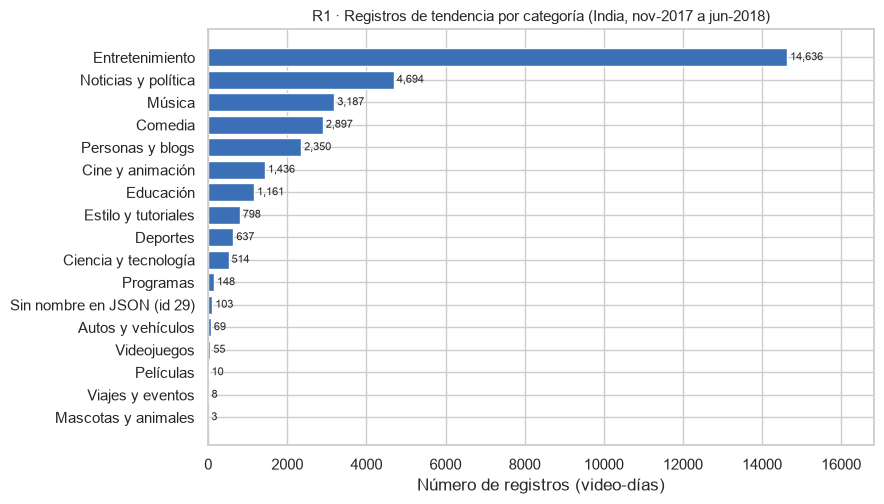

In [ ]:
r1 = (base.groupby("categoria").agg(registros=("video_key", "size"), videos_unicos=("video_key", "nunique"), dias_presencia=("trending_date", "nunique"))
        .sort_values("registros", ascending=False))
r1["% registros"] = r1["registros"] / r1["registros"].sum() * 100
r1["registros por video"] = r1["registros"] / r1["videos_unicos"]
display(r1.style.format({"registros": "{:,.0f}", "videos_unicos": "{:,.0f}", "% registros": "{:.1f}", "registros por video": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(9, 5.2))
barras_h(r1["registros"], "R1 · Registros de tendencia por categoría (India, nov-2017 a jun-2018)", "Número de registros (video-días)", ax)
plt.tight_layout(); plt.show()

**Interpretación (lo que muestran los datos).** La lista de tendencia en la India está muy concentrada: **Entretenimiento** reúne 14.636 de los 32.706 registros (44,8 %), seguida de **Noticias y política** (4.694; 14,4 %), **Música** (3.187; 9,7 %), **Comedia** (2.897; 8,9 %) y **Personas y blogs** (2.350; 7,2 %). Las tres primeras suman el 68,8 % de los registros y las cinco primeras el 84,9 %. Siete categorías aparecen en 204–205 de los 205 días con datos; en el otro extremo, Autos y vehículos (69), Videojuegos (55), Películas (10), Viajes y eventos (8) y Mascotas y animales (3) casi no llegan a tendencia. Música (2,59), Comedia (2,57) y Cine y animación (2,73) acumulan más registros por video que Educación (1,44), es decir, sus videos permanecen más días en la lista.

**Implicación para el negocio.** Quien compita por visibilidad en tendencia lo hará sobre todo en Entretenimiento, Noticias y Música. La presencia no equivale a rendimiento: indica qué contenido logró entrar a la lista en este país y periodo, no cuál rinde mejor (ver R2–R4).

**Nota sobre el código 29.** Aparece en el CSV pero no en el JSON de categorías, por lo que se conserva con la etiqueta «Sin nombre en JSON (id 29)». Representa el 0,3 % de los registros y no altera el ranking. No se le asigna un nombre porque no consta en los archivos entregados.

### R2. ¿Qué categorías concentran mayor y menor cantidad de "Me gusta" y "No me gusta"?
- **Indicador:** suma por categoría de los "me gusta" y "no me gusta" **máximos por video** (regla de acumulados de 4.1); se añade el promedio por video para no confundir volumen con tamaño de la categoría.
- **Variables y unidad:** `likes`, `dislikes` por video; unidad = video; resultado en millones.

,videos,likes,dislikes,likes_por_video,dislikes_por_video
categoria,,,,,
Entretenimiento,"7,666","85,067,062","6,781,996","11,097",885
Música,"1,228","55,669,592","3,191,091","45,334","2,599"
Comedia,"1,129","39,181,545","1,619,550","34,705","1,434"
Cine y animación,524,"14,767,377","944,619","28,182","1,803"
Deportes,350,"9,763,767","419,212","27,896","1,198"
Ciencia y tecnología,305,"9,664,531","398,889","31,687","1,308"
Personas y blogs,"1,243","8,853,672","701,301","7,123",564
Noticias y política,"2,545","5,849,402","997,987","2,298",392
Estilo y tutoriales,483,"4,334,293","431,269","8,974",893


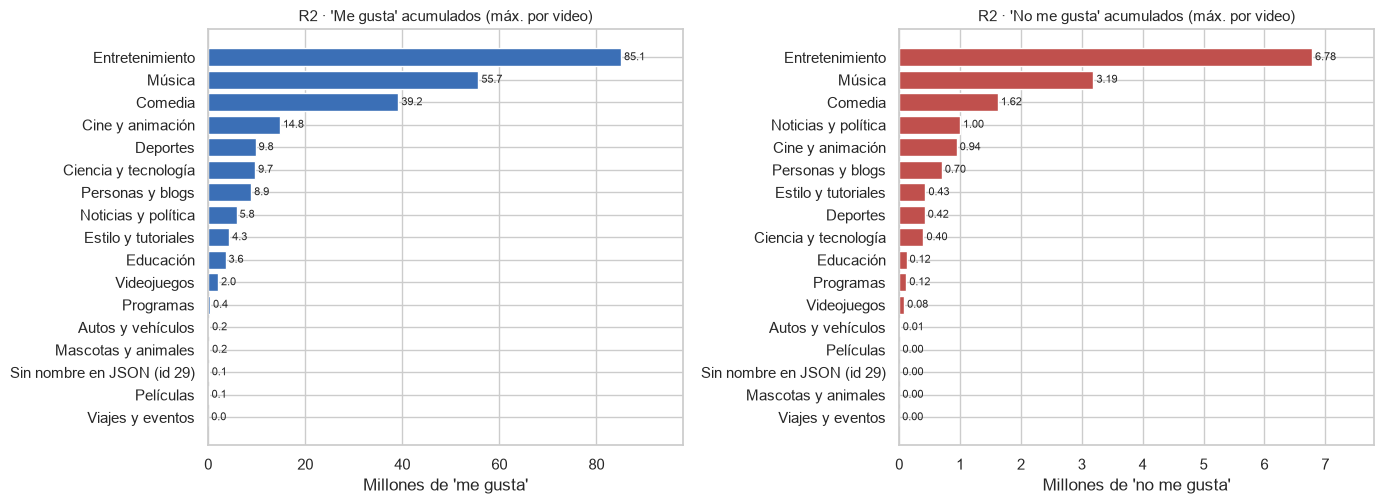

Mayor / menor en 'me gusta': Entretenimiento / Viajes y eventos
Mayor / menor en 'no me gusta': Entretenimiento / Viajes y eventos


In [ ]:
r2 = (videos.groupby("categoria").agg(videos=("video_key", "size"), likes=("likes", "sum"), dislikes=("dislikes", "sum"))
        .sort_values("likes", ascending=False))
r2["likes_por_video"] = r2["likes"] / r2["videos"]
r2["dislikes_por_video"] = r2["dislikes"] / r2["videos"]
display(r2.style.format({"videos": "{:,.0f}", "likes": "{:,.0f}", "dislikes": "{:,.0f}", "likes_por_video": "{:,.0f}", "dislikes_por_video": "{:,.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
barras_h((r2["likes"] / 1e6).sort_values(ascending=False), "R2 · 'Me gusta' acumulados (máx. por video)", "Millones de 'me gusta'", axes[0], fmt="{:,.1f}")
barras_h((r2["dislikes"] / 1e6).sort_values(ascending=False), "R2 · 'No me gusta' acumulados (máx. por video)", "Millones de 'no me gusta'", axes[1], fmt="{:,.2f}", colores="#c0504d")
plt.tight_layout(); plt.show()
print("Mayor / menor en 'me gusta':", r2["likes"].idxmax(), "/", r2["likes"].idxmin())
print("Mayor / menor en 'no me gusta':", r2["dislikes"].idxmax(), "/", r2["dislikes"].idxmin())

**Interpretación.** Entretenimiento concentra la mayor cantidad de "me gusta" (85,1 millones; 35,5 % del total) y de "no me gusta" (6,8 millones; 42,8 %), seguido de **Música** (55,7 M de "me gusta"; 23,2 %) y **Comedia** (39,2 M; 16,3 %). Entre las tres suman cerca de tres cuartas partes de los "me gusta" acumulados. Las categorías con menos son Viajes y eventos (13.048 "me gusta" y 387 "no me gusta"), Películas, Mascotas y animales y Autos y vehículos, pero tienen apenas entre 2 y 34 videos.

**Volumen no es rendimiento por video.** Por video, Música obtiene 45.334 "me gusta" y Comedia 34.705, frente a 11.097 de Entretenimiento y 2.298 de Noticias y política: Entretenimiento lidera el total porque tiene muchísimos videos (7.666), no porque cada uno interactúe más. Videojuegos (96.556) y Mascotas (93.806) muestran promedios altos, pero con 21 y 2 videos no son fiables.

**Implicación para el negocio.** Para campañas de interacción por video conviene mirar Música, Comedia, Cine y animación, Deportes y Ciencia y tecnología; Entretenimiento ofrece volumen, no intensidad.

### R3. ¿Qué categorías muestran una proporción más favorable entre "Me gusta" y "No me gusta"?
- **Indicador:** **proporción de me gusta** = Σ likes / (Σ likes + Σ dislikes) por categoría (rango 0–1; más alto = más favorable). Se complementa con "me gusta por cada no me gusta".
- **Por qué esta forma:** dividir por *likes + dislikes* evita el denominador cero que tendría `likes / dislikes` cuando un video no tiene "no me gusta", y acota el indicador entre 0 y 1.
- **Tratamiento de ceros y no disponibles:** se excluyen los videos con valoraciones desactivadas (el 0 es "no disponible") y los de likes + dislikes = 0 (sin información). Los ceros genuinos en solo uno de los dos sí se conservan.
- **Variables y unidad:** `likes`, `dislikes` por video (máximo observado); unidad = video.

,videos_usables,likes,dislikes,videos_excluidos,prop_likes,likes_por_dislike,mediana_prop_video
categoria,,,,,,,
Mascotas y animales,2,"187,613","3,453",0,0.982,54.3,0.946
Viajes y eventos,4,"13,048",387,0,0.971,33.7,0.946
Educación,708,"3,572,682","119,926",99,0.968,29.8,0.979
Sin nombre en JSON (id 29),48,"127,654","4,730",21,0.964,27.0,0.968
Videojuegos,21,"2,027,678","81,727",0,0.961,24.8,0.961
Ciencia y tecnología,304,"9,664,531","398,889",1,0.960,24.2,0.962
Comedia,"1,129","39,181,545","1,619,550",0,0.960,24.2,0.955
Deportes,346,"9,763,767","419,212",4,0.959,23.3,0.929
Autos y vehículos,33,"189,163","9,158",0,0.954,20.7,0.907


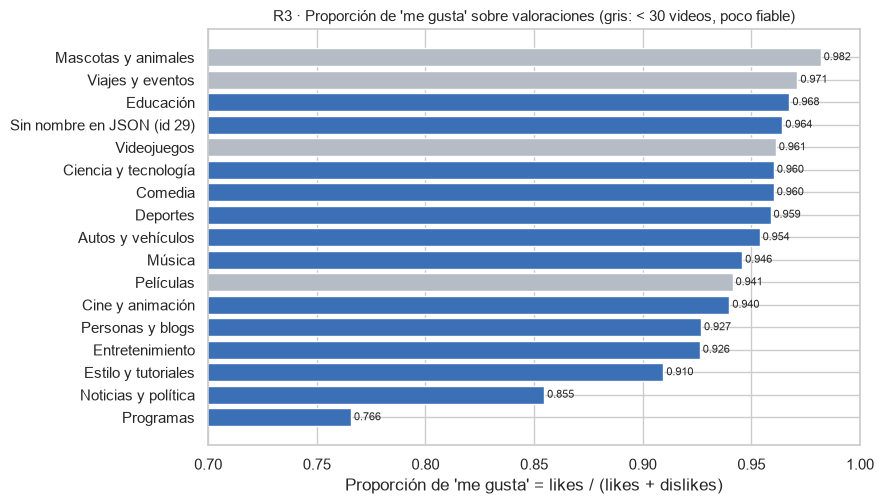

Entre categorías con >= 30 videos -> más favorable: Educación (0.968) | menos favorable: Programas (0.766)


In [ ]:
v3 = videos[(~videos.ratings_disabled) & ((videos.likes + videos.dislikes) > 0)]
r3 = v3.groupby("categoria").agg(videos_usables=("video_key", "size"), likes=("likes", "sum"), dislikes=("dislikes", "sum"))
r3["videos_excluidos"] = videos.groupby("categoria").size().reindex(r3.index) - r3["videos_usables"]
r3["prop_likes"] = r3["likes"] / (r3["likes"] + r3["dislikes"])
r3["likes_por_dislike"] = r3["likes"] / r3["dislikes"].replace(0, np.nan)
r3["mediana_prop_video"] = v3.assign(p=v3.likes / (v3.likes + v3.dislikes)).groupby("categoria")["p"].median()
r3 = r3.sort_values("prop_likes", ascending=False)
display(r3.style.format({"videos_usables": "{:,.0f}", "likes": "{:,.0f}", "dislikes": "{:,.0f}", "prop_likes": "{:.3f}", "likes_por_dislike": "{:.1f}", "mediana_prop_video": "{:.3f}"}))

colores = [PALETA if n >= MIN_N else GRIS for n in r3["videos_usables"]]
fig, ax = plt.subplots(figsize=(9, 5.2))
barras_h(r3["prop_likes"], f"R3 · Proporción de 'me gusta' sobre valoraciones (gris: < {MIN_N} videos, poco fiable)", "Proporción de 'me gusta' = likes / (likes + dislikes)", ax, fmt="{:.3f}", colores=colores)
ax.set_xlim(0.7, 1.0)
plt.tight_layout(); plt.show()
fiables = r3[r3.videos_usables >= MIN_N]
print("Entre categorías con >= 30 videos -> más favorable:", fiables["prop_likes"].idxmax(), f"({fiables['prop_likes'].max():.3f})", "| menos favorable:", fiables["prop_likes"].idxmin(), f"({fiables['prop_likes'].min():.3f})")

**Interpretación.** En conjunto, el 93,8 % de las valoraciones son "me gusta". Entre las categorías con al menos 30 videos, la proporción más favorable es **Educación (0,968; ≈ 29,8 "me gusta" por cada "no me gusta")**, seguida de Ciencia y tecnología y Comedia (0,960) y Deportes (0,959). La categoría «Sin nombre en JSON (id 29)» (48 videos usables) tendría 0,964, pero se omite de la lectura porque no tiene un nombre que permita interpretarla. Las menos favorables son **Noticias y política (0,855; 5,9 "me gusta" por "no me gusta")** y, sobre todo, **Programas (0,766; 3,3 por 1)**. La mediana por video confirma el orden (Educación 0,979; Noticias 0,863; Programas 0,794). Las categorías en gris (Mascotas, Viajes, Películas, Videojuegos) tienen menos de 30 videos y no permiten concluir.

**Cautelas.** Se excluyeron los videos con valoraciones desactivadas (por ejemplo 99 de 807 en Educación y 124 de 2.545 en Noticias), por lo que la medida describe solo a los videos que permiten valorar. Las diferencias entre las categorías de la parte alta (0,96–0,97) son pequeñas. Es una proporción de valoraciones, no una medida del sentimiento de toda la audiencia.

**Implicación para el negocio.** Educación, Ciencia y tecnología, Comedia y Deportes ofrecen un entorno de recepción más favorable; Noticias y política y Programas concentran más rechazo relativo y pueden implicar más riesgo reputacional para marcas sensibles.

### R4. ¿Cómo se relacionan las vistas y los comentarios entre categorías?
- **Indicador principal:** **comentarios por cada 1.000 vistas** = Σ comentarios / Σ vistas × 1000. Sentido: *a mayor valor, más conversación por unidad de audiencia*.
- **Indicador inverso (para no confundirlos):** **vistas por comentario** = Σ vistas / Σ comentarios. Sentido contrario: *a mayor valor, menos conversación* (hacen falta más vistas para obtener un comentario). No equivale a "comentarios por vista".
- **Tratamiento:** se excluyen los videos con comentarios desactivados (el 0 es "no disponible"); los videos con comentarios activos y 0 comentarios sí se incluyen.
- **Variables y unidad:** `views`, `comentarios` por video (máximo observado); unidad = video.

,videos_usables,vistas,comentarios,comentarios_por_mil_vistas,vistas_por_comentario,mediana_com_x_mil_video
categoria,,,,,,
Ciencia y tecnología,300,"162,855,261","3,391,368",20.82,48,11.75
Mascotas y animales,2,"2,635,064","21,512",8.16,122,4.74
Educación,689,"69,773,735","463,099",6.64,151,6.23
Sin nombre en JSON (id 29),27,"1,386,573","7,078",5.10,196,3.03
Autos y vehículos,31,"6,605,693","26,827",4.06,246,1.27
Comedia,"1,129","806,613,133","3,157,794",3.91,255,2.84
Viajes y eventos,4,"771,631","2,236",2.90,345,1.15
Videojuegos,21,"69,367,241","181,756",2.62,382,2.58
Entretenimiento,"7,466","4,336,360,762","9,137,451",2.11,475,0.54


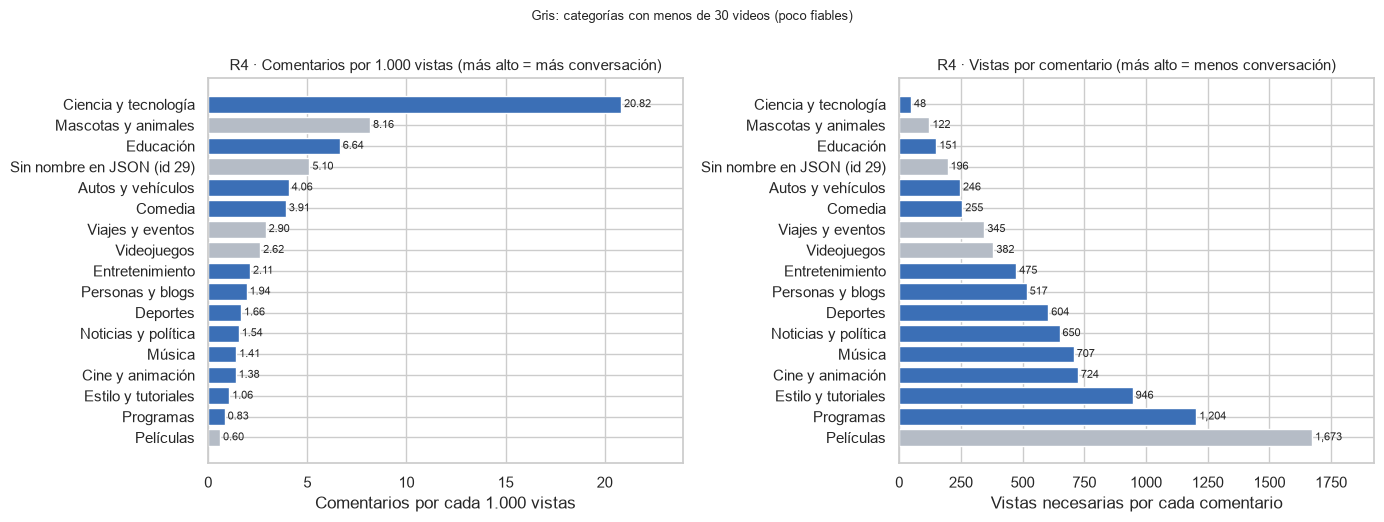

In [ ]:
v4 = videos[~videos.comments_disabled]
r4 = v4.groupby("categoria").agg(videos_usables=("video_key", "size"), vistas=("views", "sum"), comentarios=("comentarios", "sum"))
r4["comentarios_por_mil_vistas"] = r4["comentarios"] / r4["vistas"] * 1000
r4["vistas_por_comentario"] = r4["vistas"] / r4["comentarios"]
r4["mediana_com_x_mil_video"] = v4.assign(t=v4.comentarios / v4.views * 1000).groupby("categoria")["t"].median()
r4 = r4.sort_values("comentarios_por_mil_vistas", ascending=False)
display(r4.style.format({"videos_usables": "{:,.0f}", "vistas": "{:,.0f}", "comentarios": "{:,.0f}", "comentarios_por_mil_vistas": "{:.2f}", "vistas_por_comentario": "{:,.0f}", "mediana_com_x_mil_video": "{:.2f}"}))

colores = [PALETA if n >= MIN_N else GRIS for n in r4["videos_usables"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
barras_h(r4["comentarios_por_mil_vistas"], f"R4 · Comentarios por 1.000 vistas (más alto = más conversación)", "Comentarios por cada 1.000 vistas", axes[0], fmt="{:.2f}", colores=colores)
r4b = r4["vistas_por_comentario"].sort_values()
colores_b = [PALETA if r4.loc[k, "videos_usables"] >= MIN_N else GRIS for k in r4b.index]
barras_h(r4b, "R4 · Vistas por comentario (más alto = menos conversación)", "Vistas necesarias por cada comentario", axes[1], fmt="{:,.0f}", colores=colores_b)
fig.suptitle(f"Gris: categorías con menos de {MIN_N} videos (poco fiables)", y=1.0, fontsize=9)
plt.tight_layout(); plt.show()

**Cómo leer los indicadores.** *Comentarios por 1.000 vistas*: más alto = más conversación. *Vistas por comentario*: más alto = menos conversación (es la lectura inversa). Para el conjunto, hay **2,22 comentarios por cada 1.000 vistas**, es decir, un comentario cada ≈ 450 vistas.

**Interpretación.** **Ciencia y tecnología** muestra la mayor conversación (20,8 comentarios por 1.000 vistas; un comentario cada 48 vistas), seguida de Educación (6,6; cada 151), Autos y vehículos (4,1; cada 246; solo 31 videos, apenas sobre el umbral de 30) y Comedia (3,9; cada 255; 1.129 videos). Se destaca a Comedia entre las primeras porque su base es mucho más amplia y, por tanto, más estable. La menor conversación se observa en **Programas** (0,83; cada 1.204 vistas), Estilo y tutoriales (1,06; cada 946), Cine y animación (1,38) y Música (1,41; cada 707). El valor de Ciencia y tecnología está empujado por unos pocos videos muy comentados; aun así, su mediana por video (11,8 por 1.000) sigue siendo la más alta, y la de Educación (6,2) la segunda. Música combina muchos "me gusta" (R2) con poca conversación: su audiencia valora pero comenta poco.

**Cautelas.** Se excluyeron los videos con comentarios desactivados. Más comentarios no significa comentarios positivos. Las categorías en gris tienen menos de 30 videos. **El valor de Ciencia y tecnología depende de pocos videos:** los 10 más comentados concentran el 57 % de sus comentarios y los 3 primeros, el 31 %. Sin esos 3, la categoría baja de 20,8 a 14,8 comentarios por 1.000 vistas, que sigue siendo la más alta; la conclusión se mantiene, pero con menos holgura.

**Implicación para el negocio.** Si la meta es generar conversación y comunidad, Ciencia y tecnología, Educación y Comedia son más favorables; si la meta es alcance masivo, Música y Entretenimiento ofrecen audiencia aunque con menos comentarios por vista.

### R5. ¿Cómo cambia el número de registros y de videos únicos en tendencia a lo largo del periodo?
- **Indicador:** por día, número de **registros** (videos en la lista ese día; como se conserva un registro por video y día, coincide con los videos distintos de ese día) y número de **videos nuevos** (primer día en tendencia). Por mes: registros, videos únicos y registros por video (permanencia).
- **Variables y unidad:** `trending_date`, `video_key`; unidad = día y mes. Los 8 días sin datos se muestran como cortes de la línea.

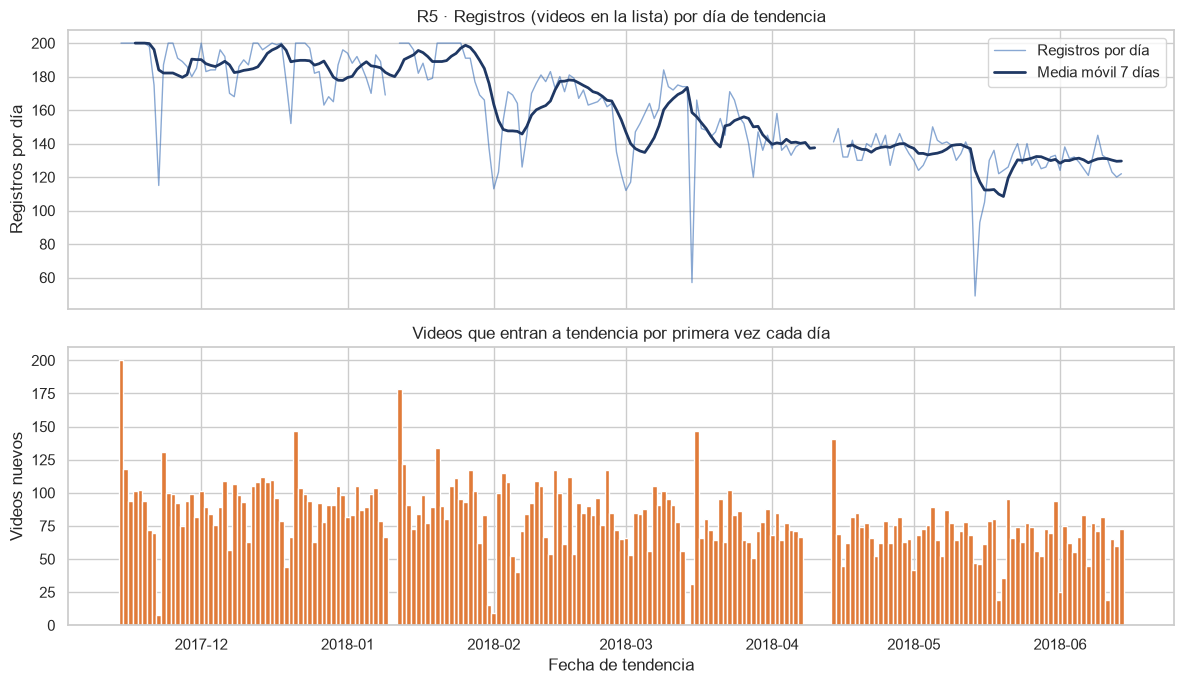

,dias_con_datos,registros,videos_unicos,registros_por_dia,registros_por_video
mes,,,,,
2017-11,17,"3,206","1,631",188.6,1.97
2017-12,31,"5,803","2,958",187.2,1.96
2018-01,29,"5,414","2,806",186.7,1.93
2018-02,28,"4,518","2,415",161.4,1.87
2018-03,31,"4,663","2,405",150.4,1.94
2018-04,24,"3,329","1,815",138.7,1.83
2018-05,31,"3,966","2,159",127.9,1.84
2018-06,14,"1,807",958,129.1,1.89


Registros por día -> mínimo: 49 | mediana: 163 | máximo: 200
Días sin datos: 8


In [ ]:
idx = pd.date_range(base.trending_date.min(), base.trending_date.max())
diario = base.groupby("trending_date").agg(registros=("video_key", "size")).reindex(idx)
diario["videos_nuevos"] = videos.groupby("primer_dia").size().reindex(idx)
diario["media_7d"] = diario["registros"].rolling(7, min_periods=4).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(diario.index, diario["registros"], color=PALETA, lw=1, alpha=.6, label="Registros por día")
axes[0].plot(diario.index, diario["media_7d"], color="#1f3864", lw=2, label="Media móvil 7 días")
axes[0].set_title("R5 · Registros (videos en la lista) por día de tendencia"); axes[0].set_ylabel("Registros por día"); axes[0].legend()
axes[1].bar(diario.index, diario["videos_nuevos"], color="#e07b39", width=1)
axes[1].set_title("Videos que entran a tendencia por primera vez cada día"); axes[1].set_ylabel("Videos nuevos"); axes[1].set_xlabel("Fecha de tendencia")
plt.tight_layout(); plt.show()

mensual = base.assign(mes=base.trending_date.dt.to_period("M")).groupby("mes").agg(
    dias_con_datos=("trending_date", "nunique"), registros=("video_key", "size"), videos_unicos=("video_key", "nunique"))
mensual["registros_por_dia"] = mensual["registros"] / mensual["dias_con_datos"]
mensual["registros_por_video"] = mensual["registros"] / mensual["videos_unicos"]
display(mensual.style.format({"registros": "{:,.0f}", "videos_unicos": "{:,.0f}", "registros_por_dia": "{:.1f}", "registros_por_video": "{:.2f}"}))
print("Registros por día -> mínimo:", int(diario.registros.min()), "| mediana:", int(diario.registros.median()), "| máximo:", int(diario.registros.max()))
print("Días sin datos:", int(diario.registros.isna().sum()))

**Interpretación.** Los registros por día pasan de ≈ 188 en noviembre de 2017, diciembre y enero (media mensual 186–189) a ≈ 128–129 en mayo y junio de 2018; comparando los primeros y últimos 30 días la caída es de ≈ 31 % (188 → 129). El máximo diario es 200 registros, lo que sugiere un tope de 200 videos por lista. Los videos únicos mensuales muestran la misma tendencia (diciembre 2.958; mayo 2.159, ambos de 31 días). En cambio, los **registros por video se mantienen estables (1,83–1,97)**: no cambió cuánto permanece cada video, cambió cuántos videos hay en la lista. El mínimo diario (49 registros, el 14 de mayo de 2018) y los **8 días sin datos** (10–11 de enero y 8–13 de abril de 2018) son vacíos o días incompletos de la fuente; noviembre y junio son meses parciales, por lo que se comparan por día.

**Implicación para el negocio.** La lista fue haciéndose más selectiva: menos videos por día compiten por la visibilidad. Parte de la caída puede deberse a cómo se recolectó la lista; con estos datos no es posible distinguir una causa.

### R6. ¿Qué canales aparecen con mayor y menor frecuencia en los registros?
- **Indicador:** número de registros por canal (frecuencia); complementos: videos únicos y días de presencia. Se reporta también la **concentración** (porcentaje de registros de los 10 canales principales).
- **Variables y unidad:** `channel_title`; unidad = registro.

Canales distintos: 1,426 | registros totales: 32,706
Concentración: los 10 canales principales suman 6.1% de los registros; los 50 principales, 23.8%
Canales con un solo registro: 129 (9.0% de los canales)

Mayor frecuencia (top 15):


,registros,videos_unicos,dias_presencia,registros_por_video
channel_title,,,,
VikatanTV,204,156,204,1.31
etvteluguindia,204,154,204,1.32
SAB TV,203,134,203,1.51
ETV Plus India,203,130,203,1.56
Study IQ education,202,171,202,1.18
Flowers Comedy,201,117,201,1.72
Tarang TV,199,158,199,1.26
Mazhavil Manorama,195,141,195,1.38
SET India,195,97,195,2.01


Menor frecuencia: muestra reproducible de canales con 1 solo registro (semilla 1280):


,registros,videos_unicos,dias_presencia,registros_por_video
channel_title,,,,
Kannada Suddi,1,1,1,1.00
Bollywood Sins,1,1,1,1.00
Life Hacks,1,1,1,1.00
Viral in India,1,1,1,1.00
Half Ticket Media,1,1,1,1.00
YouTube Got Talent,1,1,1,1.00
WowShow,1,1,1,1.00
Punjabi Live Shows,1,1,1,1.00


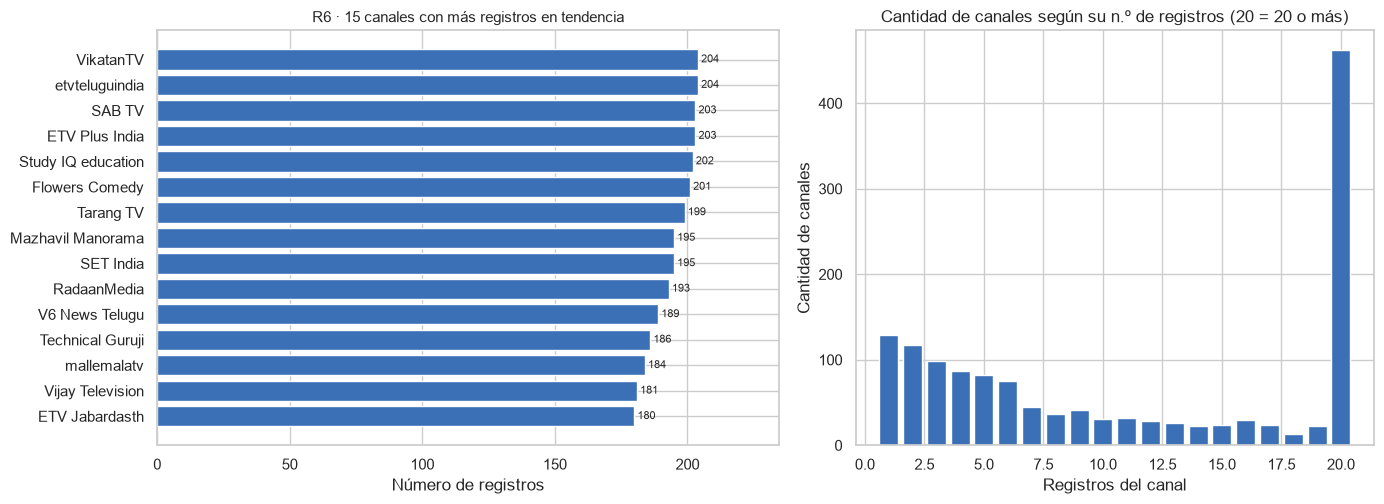

In [ ]:
r6 = (base.groupby("channel_title").agg(registros=("video_key", "size"), videos_unicos=("video_key", "nunique"), dias_presencia=("trending_date", "nunique"))
        .sort_values(["registros", "videos_unicos"], ascending=False))
r6["registros_por_video"] = r6["registros"] / r6["videos_unicos"]
print(f"Canales distintos: {len(r6):,} | registros totales: {r6.registros.sum():,}")
print(f"Concentración: los 10 canales principales suman {r6.registros.head(10).sum()/r6.registros.sum():.1%} de los registros; los 50 principales, {r6.registros.head(50).sum()/r6.registros.sum():.1%}")
print(f"Canales con un solo registro: {(r6.registros == 1).sum():,} ({(r6.registros == 1).mean():.1%} de los canales)")

print("\nMayor frecuencia (top 15):")
display(r6.head(15).style.format({"registros_por_video": "{:.2f}"}))
print("Menor frecuencia: muestra reproducible de canales con 1 solo registro (semilla 1280):")
display(r6[r6.registros == 1].sample(8, random_state=1280))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
barras_h(r6["registros"].head(15), "R6 · 15 canales con más registros en tendencia", "Número de registros", axes[0])
dist = r6["registros"].clip(upper=20).value_counts().sort_index()
axes[1].bar(dist.index, dist.values, color=PALETA)
axes[1].set_title("Cantidad de canales según su n.º de registros (20 = 20 o más)"); axes[1].set_xlabel("Registros del canal"); axes[1].set_ylabel("Cantidad de canales")
plt.tight_layout(); plt.show()

**Interpretación.** Aparecen **1.426 canales** y la frecuencia está **poco concentrada**: los 10 canales principales suman solo el 6,1 % de los registros y los 50 principales el 23,8 %. Los más frecuentes son **VikatanTV (204 registros; 156 videos distintos), etvteluguindia (204), SAB TV (203), ETV Plus India (203) y Study IQ education (202)**; son en su mayoría canales de televisión regionales (más Study IQ education, de contenido educativo) que aparecen casi todos los días del periodo con videos distintos (1,2 a 2 registros por video). En el otro extremo, **129 canales (9,0 %) aparecen una sola vez** (ejemplos: Kannada Suddi, Life Hacks, WowShow).

**Cautelas.** Frecuencia en tendencia no es tamaño de audiencia, y el nombre del canal podría estar escrito de formas distintas.

**Implicación para el negocio.** Existe un grupo de canales con presencia sostenida que son candidatos naturales a alianzas de largo plazo; al mismo tiempo, la larga cola de canales de aparición única indica que entrar a tendencia no es exclusivo de los canales grandes.

### R7. ¿En qué Estados se presenta el mayor número de "Vistas", "Me gusta" y "No me gusta"?
> ⚠️ **SIMULACIÓN.** Los Estados (`state`) fueron asignados al azar a cada fila; **no representan la ubicación real de los videos ni de la audiencia**. Este ejercicio se presenta solo para cumplir el requerimiento y se **excluye de las evidencias para decisiones comerciales**. Se demuestra además que el resultado solo refleja el azar.
- **Indicador:** suma por Estado simulado de las vistas, "me gusta" y "no me gusta" máximos por video (el Estado de un video es el de su primer registro).

,videos,vistas,likes,dislikes,vistas_por_video
estado_sim,,,,,
Haryana,528,"493,772,611","10,505,564","757,560","935,175"
Chhattisgarh,492,"444,367,186","8,301,048","1,939,402","903,185"
Andaman And Nicobar,510,"424,114,020","10,582,670","543,320","831,596"
Dadra And Nagar Haveli,508,"416,502,531","9,289,887","733,143","819,887"
Nagaland,503,"413,580,064","7,571,356","660,298","822,227"
Karnataka,502,"395,655,478","8,425,569","502,230","788,158"
Goa,546,"392,052,671","8,692,425","484,022","718,045"
Manipur,475,"391,419,461","8,280,166","507,062","824,041"
Orissa,519,"384,079,312","7,059,583","454,452","740,037"


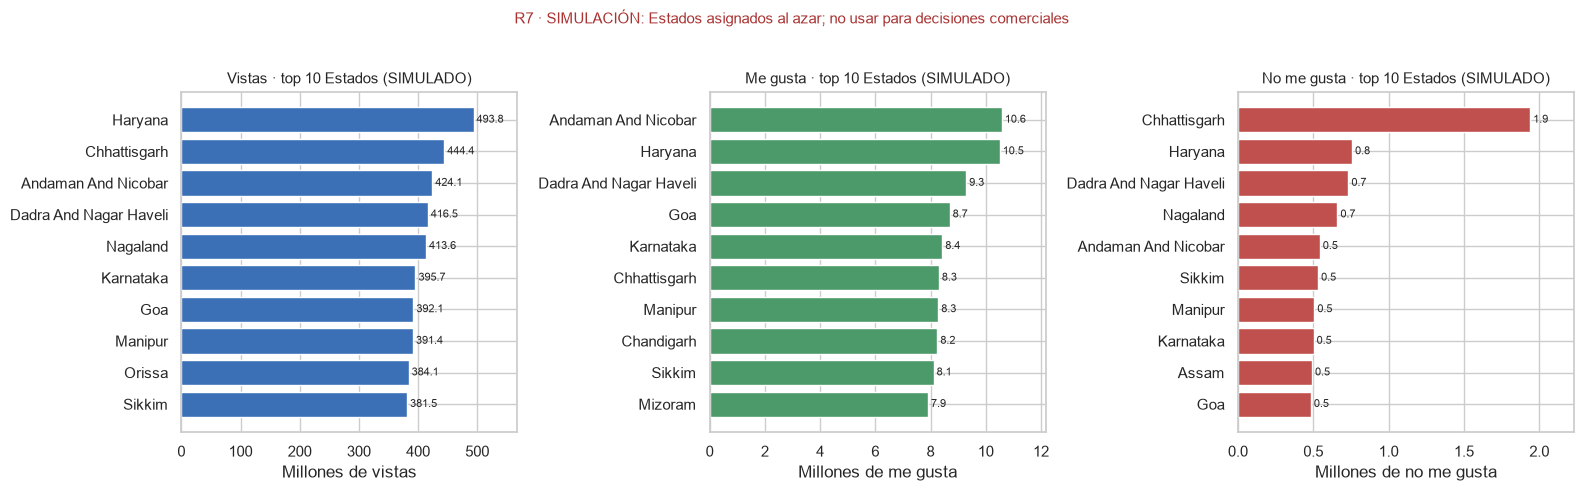

Correlación (Spearman) entre n.º de videos por Estado y vistas totales por Estado: 0.51
Vistas por video entre Estados: mínimo 547,531 - máximo 935,175 (razón 1.71)
Videos por Estado: mínimo 458 - máximo 546


In [ ]:
r7 = (videos.groupby("estado_sim").agg(videos=("video_key", "size"), vistas=("views", "sum"), likes=("likes", "sum"), dislikes=("dislikes", "sum"))
        .sort_values("vistas", ascending=False))
r7["vistas_por_video"] = r7["vistas"] / r7["videos"]
display(r7.head(10).style.format({"videos": "{:,.0f}", "vistas": "{:,.0f}", "likes": "{:,.0f}", "dislikes": "{:,.0f}", "vistas_por_video": "{:,.0f}"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (col, tit, color) in zip(axes, [("vistas", "Vistas", PALETA), ("likes", "Me gusta", "#4c9a6a"), ("dislikes", "No me gusta", "#c0504d")]):
    top10 = (r7[col] / 1e6).sort_values(ascending=False).head(10)
    barras_h(top10, f"{tit} · top 10 Estados (SIMULADO)", f"Millones de {tit.lower()}", ax, fmt="{:,.1f}", colores=color)
fig.suptitle("R7 · SIMULACIÓN: Estados asignados al azar; no usar para decisiones comerciales", y=1.02, color="#a33", fontsize=11)
plt.tight_layout(); plt.show()

rho = r7[["videos", "vistas"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación (Spearman) entre n.º de videos por Estado y vistas totales por Estado: {rho:.2f}")
print(f"Vistas por video entre Estados: mínimo {r7.vistas_por_video.min():,.0f} - máximo {r7.vistas_por_video.max():,.0f} (razón {r7.vistas_por_video.max()/r7.vistas_por_video.min():.2f})")
print("Videos por Estado: mínimo", r7.videos.min(), "- máximo", r7.videos.max())

**Interpretación (SIMULACIÓN).** Por vistas máximas por video, el "top" simulado lo encabezan Haryana (493,8 millones), Chhattisgarh (444,4 M) y Andaman y Nicobar (424,1 M), pero cada Estado recibió entre 458 y 546 videos por asignación aleatoria y las vistas por video varían entre 548 mil y 935 mil solo porque unos pocos videos muy vistos cayeron por azar en un Estado u otro (la correlación de Spearman entre n.º de videos y vistas por Estado es apenas 0,51). Con otra asignación aleatoria el ranking cambiaría.

**Implicación para el negocio.** Ninguna: estos resultados **no deben usarse** para decisiones geográficas ni comerciales; se presentan solo para cumplir el requerimiento. Dos señales muestran que la variable es azar: (i) la distribución por Estado es casi uniforme (entre 1.065 y 1.190 registros por Estado) y (ii) el mismo video aparece el mismo día con Estados distintos (en el 99,7 % de esos pares).

### R8. ¿Qué relación se observa entre vistas y cantidad de comentarios en los videos analizados?
- **Indicador:** correlación de Spearman (apropiada para variables asimétricas y relaciones monótonas) y de Pearson sobre logaritmos; pendiente de la recta log-log (si las vistas se multiplican por 10, los comentarios se multiplican por 10^pendiente).
- **Variables y unidad:** `views` y `comentarios` por video (máximo observado); unidad = video; solo videos con comentarios activos y al menos 1 comentario (para poder usar logaritmos).

Videos usados: 15,838 de 16,521 (excluidos: comentarios desactivados o 0 comentarios)
Spearman = 0.648 | Pearson (escala original) = 0.670 | Pearson (log10-log10) = 0.688
Pendiente log-log = 0.99  -> al multiplicar las vistas por 10, los comentarios se multiplican por 9.8 (en promedio)


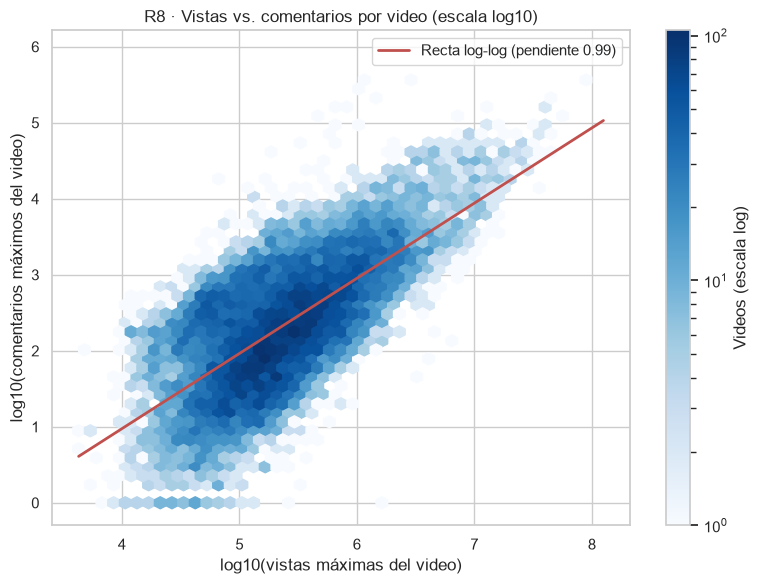

,videos,spearman
categoria,,
Deportes,340,0.863
Música,"1,224",0.856
Comedia,"1,128",0.753
Estilo y tutoriales,469,0.737
Cine y animación,499,0.714
Personas y blogs,"1,158",0.687
Entretenimiento,"7,421",0.665
Noticias y política,"2,413",0.633
Programas,110,0.631


In [ ]:
v8 = videos[(~videos.comments_disabled) & (videos.comentarios > 0)].copy()
x = np.log10(v8["views"]); y = np.log10(v8["comentarios"])
spearman = v8["views"].corr(v8["comentarios"], method="spearman")
pearson_raw = v8["views"].corr(v8["comentarios"])
pearson_log = x.corr(y)
pend, inter = np.polyfit(x, y, 1)
print(f"Videos usados: {len(v8):,} de {len(videos):,} (excluidos: comentarios desactivados o 0 comentarios)")
print(f"Spearman = {spearman:.3f} | Pearson (escala original) = {pearson_raw:.3f} | Pearson (log10-log10) = {pearson_log:.3f}")
print(f"Pendiente log-log = {pend:.2f}  -> al multiplicar las vistas por 10, los comentarios se multiplican por {10**pend:.1f} (en promedio)")

fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(x, y, gridsize=45, cmap="Blues", mincnt=1, bins="log")
xs = np.linspace(x.min(), x.max(), 50); ax.plot(xs, inter + pend * xs, color="#c0504d", lw=2, label=f"Recta log-log (pendiente {pend:.2f})")
fig.colorbar(hb, label="Videos (escala log)")
ax.set_title("R8 · Vistas vs. comentarios por video (escala log10)"); ax.set_xlabel("log10(vistas máximas del video)"); ax.set_ylabel("log10(comentarios máximos del video)"); ax.legend()
plt.tight_layout(); plt.show()

por_cat = (v8.groupby("categoria").apply(lambda g: pd.Series({"videos": len(g), "spearman": g["views"].corr(g["comentarios"], method="spearman")}))
             .query("videos >= @MIN_N").sort_values("spearman", ascending=False))
display(por_cat.style.format({"videos": "{:,.0f}", "spearman": "{:.3f}"}))

**Interpretación.** Con 15.838 videos, la relación entre vistas y comentarios es **positiva y de intensidad moderada a alta** (Spearman 0,648; Pearson sobre logaritmos 0,688). La pendiente log-log ≈ 0,99 indica una relación casi proporcional: cuando las vistas se multiplican por 10, los comentarios se multiplican por ≈ 9,8; es decir, en promedio la tasa de comentarios por vista se mantiene constante. La relación es más fuerte en **Deportes (0,863) y Música (0,856)** y más débil en Educación (0,577), Ciencia y tecnología (0,602) y Autos (0,478, con 31 videos): en estas últimas los comentarios dependen más de otros factores que del tamaño de la audiencia.

**Cautelas.** Es una asociación, no causalidad; ambos crecen con la popularidad del video. Se excluyeron 683 videos con comentarios desactivados o sin comentarios (4,1 %). Comentar no implica opinar positivamente.

**Implicación para el negocio.** Los comentarios sirven como indicador aproximado del alcance, pero la tasa varía por categoría (R4), por lo que conviene compararlos solo dentro de la misma categoría.

### R9. Pregunta adicional: ¿cuánto tardan los videos en llegar a tendencia y cuántos días permanecen, según su categoría?
**Por qué es útil para el cliente:** indica la **ventana de oportunidad** para lanzar o impulsar contenido: si la mayoría de videos entra a tendencia en 1–2 días, una campaña debe activarse de inmediato; y la permanencia mide cuánto dura la exposición una vez dentro.
- **Indicadores:** (a) días entre la publicación y el primer registro de tendencia; (b) número de días (registros) que el video permanece en tendencia.
- **Variables y unidad:** `dias_a_tendencia` (primer registro) y `n_registros` por video; unidad = video; se muestran categorías con al menos 30 videos.

,mediana,media,percentil 90
Días hasta tendencia,1.00,1.30,2.00
Días en tendencia,2.00,2.00,4.00


Videos que entran a tendencia a los 0-1 días de publicados: 74.0% | en 3 días o menos: 99.0%
Videos que permanecen un solo día: 48.0% | 5 días o más: 5.2%


,videos,mediana_dias_a_tendencia,pct_entra_en_2_dias,mediana_dias_en_tendencia,media_dias_en_tendencia
categoria,,,,,
Autos y vehículos,33,1.000000,100.0,2.000000,2.03
Ciencia y tecnología,305,1.000000,97.7,1.000000,1.70
Cine y animación,524,1.000000,94.1,3.000000,2.73
Comedia,"1,129",1.000000,96.7,2.000000,2.57
Deportes,350,1.000000,96.9,1.000000,1.81
Educación,807,1.000000,99.0,1.000000,1.44
Entretenimiento,"7,666",1.000000,96.8,1.000000,1.91
Estilo y tutoriales,483,1.000000,96.9,1.000000,1.65
Música,"1,228",1.000000,96.3,2.000000,2.60


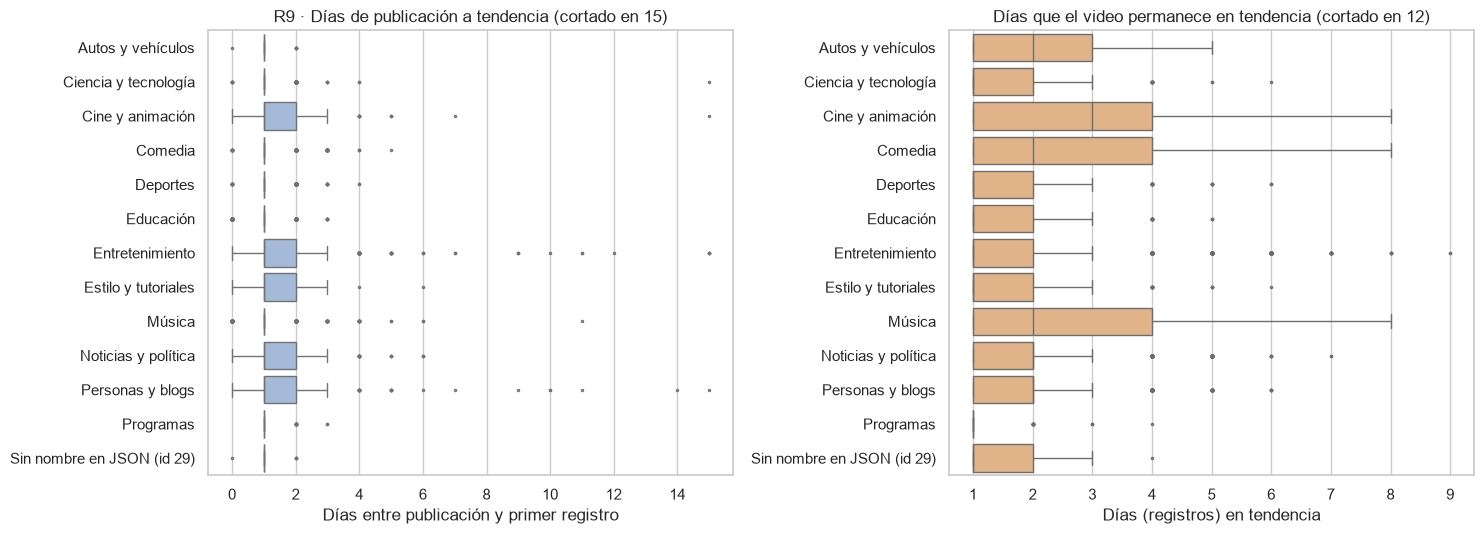

In [ ]:
v9 = videos.copy()
resumen_global = pd.DataFrame({"mediana": [v9.dias_a_tendencia.median(), v9.n_registros.median()],
                               "media": [v9.dias_a_tendencia.mean(), v9.n_registros.mean()],
                               "percentil 90": [v9.dias_a_tendencia.quantile(.9), v9.n_registros.quantile(.9)]},
                              index=["Días hasta tendencia", "Días en tendencia"])
display(resumen_global.round(1))
print(f"Videos que entran a tendencia a los 0-1 días de publicados: {(v9.dias_a_tendencia <= 1).mean():.1%} | en 3 días o menos: {(v9.dias_a_tendencia <= 3).mean():.1%}")
print(f"Videos que permanecen un solo día: {(v9.n_registros == 1).mean():.1%} | 5 días o más: {(v9.n_registros >= 5).mean():.1%}")

r9 = (v9.groupby("categoria").agg(videos=("video_key", "size"), mediana_dias_a_tendencia=("dias_a_tendencia", "median"),
                                   pct_entra_en_2_dias=("dias_a_tendencia", lambda s: (s <= 2).mean() * 100),
                                   mediana_dias_en_tendencia=("n_registros", "median"), media_dias_en_tendencia=("n_registros", "mean"))
        .query("videos >= @MIN_N").sort_values("mediana_dias_a_tendencia"))
display(r9.style.format({"videos": "{:,.0f}", "pct_entra_en_2_dias": "{:.1f}", "media_dias_en_tendencia": "{:.2f}"}))

orden = r9.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=v9[v9.categoria.isin(orden)], y="categoria", x=v9["dias_a_tendencia"].clip(upper=15), order=orden, color="#9db8e0", fliersize=1.5, ax=axes[0])
axes[0].set_title("R9 · Días de publicación a tendencia (cortado en 15)"); axes[0].set_xlabel("Días entre publicación y primer registro"); axes[0].set_ylabel("")
sns.boxplot(data=v9[v9.categoria.isin(orden)], y="categoria", x=v9["n_registros"].clip(upper=12), order=orden, color="#f0b27a", fliersize=1.5, ax=axes[1])
axes[1].set_title("Días que el video permanece en tendencia (cortado en 12)"); axes[1].set_xlabel("Días (registros) en tendencia"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** Los videos llegan rápido a tendencia: la mediana es **1 día** desde su publicación, el 74,0 % entra a los 0–1 días y el 99,0 % a los 3 días o menos. Permanecen poco: la mediana es **2 días**, el 48,0 % aparece un solo día y solo el 5,2 % llega a 5 días o más. La velocidad de entrada es casi idéntica entre categorías (mediana de 1 día; ≈ 94–100 % entra en 2 días o menos); lo que cambia es la **permanencia**: Cine y animación (media 2,73 días; mediana 3), Música (2,60) y Comedia (2,57) duran más; Programas (1,22), Educación (1,44) y Estilo y tutoriales (1,65) duran menos.

**Cautelas.** Los días se calculan como diferencia de fechas (UTC), con error de ±1 día; los videos que ya estaban en tendencia antes del 14 de noviembre de 2017 entran con su primera aparición observada. La permanencia también está truncada al final (videos todavía en la lista el 14-jun-2018) y por los 8 días sin datos de enero y abril, por lo que puede subestimar la duración real de algunos videos. Los valores difieren levemente de R1 (por ejemplo, Música 2,60 frente a 2,59) porque R1 asigna la categoría por registro y R9 por video (la de su primer registro).

**Implicación para el negocio.** La ventana de oportunidad es corta: el contenido debe activarse en las primeras 24–48 horas desde su publicación. Música, Cine y animación y Comedia ofrecen más días de exposición una vez dentro de la lista.

---
# Parte 5. Modelado y evaluación

**Propósito:** construir y evaluar un modelo predictivo alineado con el problema, con un procedimiento de prueba justificable y sin usar información que no estaría disponible al momento de predecir.

## 5.1. Definición del problema predictivo

| Elemento | Definición |
|---|---|
| **Tipo de problema** | Regresión. |
| **Variable objetivo** | `log_views` = ln(vistas) del video. Se usa el logaritmo porque las vistas son muy asimétricas (ver 2.2 y 3.2); las métricas se reportan también en la escala original. |
| **Unidad de observación** | Un **video**, en su **primer registro de tendencia** (`es_primer_registro`). Cada video aparece una sola vez, de modo que ningún video está a la vez en entrenamiento y prueba. |
| **Momento de la predicción** | El día en que el video **entra por primera vez a la lista de tendencia**. Se conocen sus atributos de publicación y los días transcurridos desde que se publicó, pero **no** sus interacciones (me gusta, no me gusta, comentarios). |
| **Tipo de tarea** | **Estimación** de las vistas que tendrá un video *en su registro de entrada a tendencia* con variables medidas ese mismo día (no es un pronóstico de vistas futuras de días posteriores). Utilidad: dimensionar el alcance esperado de un contenido que acaba de entrar a la lista. |

## 5.2. Selección de variables y técnica

**Técnica:** **regresión lineal múltiple** (`LinearRegression` de scikit-learn), tal como se trabajó en las sesiones 12 y 13: partición única, línea base de la media, modelo inicial, **diagnóstico de residuos, observaciones atípicas y multicolinealidad**, una mejora justificada por ese diagnóstico, regularización (Ridge), comparación con validación cruzada **solo sobre entrenamiento** y evaluación final en test **una sola vez**.

Candidatos: (i) línea base (media del entrenamiento), (ii) regresión lineal simple (solo `log1p(dias_a_tendencia)`), (iii) regresión lineal múltiple inicial, (iv) regresión múltiple con términos cuadráticos y (v) Ridge sobre las mismas variables que (iv).

| Predictor | Justificación y disponibilidad al predecir |
|---|---|
| `categoria` (agrupada, codificada en variables dummy) | Tipo de contenido; conocido desde la publicación. Las categorías raras (< 50 videos en entrenamiento) se agrupan en "Otras". |
| `log_dias_a_tendencia` = ln(1 + días) | Cuánto tardó en entrar a tendencia; conocido el día de entrada. |
| `franja_pub`, `dia_semana_pub` | Momento de publicación (IST); conocido al publicar. |
| `len_titulo`, `n_tags`, `len_descripcion` | Atributos editoriales del video; conocidos al publicar. |
| `comments_disabled`, `ratings_disabled` | Configuración del video; conocida el día de entrada. |

**Variables excluidas y por qué:**
- `likes`, `dislikes`, `comment_count` y todas las tasas derivadas de ellas: se miden **junto con** las vistas y las revelan indirectamente (fuga de información).
- `video_id`, `video_key`, `title`, `thumbnail_link`, `channel_title` (identificadores o texto libre sin tratamiento): sin utilidad analítica directa en este nivel del curso.
- `state`, `lat`, `lon`, `geometry`: ubicación **simulada**; no se usa como predictor.
- Registros posteriores al primero de cada video: sus vistas ya reflejan días de exposición en tendencia.

## 5.3. Plan de prueba

**Criterio de separación: temporal, una sola vez.** Los videos se ordenan por la fecha de su primer registro; el **80 % más antiguo entrena** y el **20 % más reciente prueba**. Así el modelo nunca usa información del futuro para predecir el pasado, que es lo que ocurriría al usarlo realmente. Como cada video aparece **una sola vez** (unidad de observación = primer registro), ningún video puede estar a la vez en entrenamiento y prueba; es el mismo objetivo que la separación por grupos (`GroupShuffleSplit`) de la sesión 13. La partición temporal no necesita semilla; la semilla `1280` (la del curso) se usa en la validación cruzada y en el bootstrap.

**Regla de uso de test (sesión 13):** test no se usa para explorar, transformar variables ni elegir modelo. Todas las decisiones (exploración, diagnóstico, mejora, elección de alpha y del modelo principal) se toman con **entrenamiento** y validación cruzada; test solo se usa al final para evaluar.

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 1280   # misma semilla que en los ejercicios del curso

# Unidad de observación: primer registro de cada video (un video aparece una sola vez)
M = base[base["es_primer_registro"]].copy()
M["log_dias_a_tendencia"] = np.log1p(M["dias_a_tendencia"])
M["comments_disabled"] = M["comments_disabled"].astype(int)
M["ratings_disabled"] = M["ratings_disabled"].astype(int)
M = M.sort_values(["trending_date", "video_key"]).reset_index(drop=True)

NUM = ["log_dias_a_tendencia", "len_titulo", "n_tags", "len_descripcion"]
BIN = ["comments_disabled", "ratings_disabled"]
CAT = ["categoria", "franja_pub", "dia_semana_pub"]
OBJETIVO = "log_views"

print("Videos modelables:", len(M), "| predictores:", NUM + BIN + CAT)
if M[NUM + BIN + CAT + [OBJETIVO]].isna().any().any():
    raise ValueError("Hay valores faltantes. Revisarlos antes de continuar.")
if not np.isfinite(M[NUM + BIN + [OBJETIVO]].to_numpy()).all():
    raise ValueError("Hay valores infinitos. Revisarlos antes de continuar.")
assert not ({"likes", "dislikes", "comment_count", "state", "lat", "lon", "geometry", "video_id"} & set(NUM + BIN + CAT))
M[NUM + [OBJETIVO]].describe().T.round(2)

In [ ]:
# Separación temporal UNA SOLA VEZ: 80 % más antiguo = entrenamiento, 20 % más reciente = prueba
corte = M["trending_date"].quantile(0.80)       # en M, trending_date = fecha del primer registro
train = M[M["trending_date"] <= corte].copy()
test = M[M["trending_date"] > corte].copy()
assert train.trending_date.max() < test.trending_date.min()
assert set(train.video_key).isdisjoint(set(test.video_key))

# Categorías raras definidas SOLO con el entrenamiento
conteo_train = train["categoria"].value_counts()
raras = conteo_train[conteo_train < 50].index.tolist()
for t in (train, test):
    t["categoria"] = t["categoria"].where(~t["categoria"].isin(raras), "Otras")

def codificar(df, columnas=None):
    """Variables dummy (drop_first). Las columnas se fijan con entrenamiento y se reutilizan en test."""
    X = pd.get_dummies(df[NUM + BIN + CAT], columns=CAT, drop_first=True, dtype=float)
    X[NUM + BIN] = X[NUM + BIN].astype(float)
    return X if columnas is None else X.reindex(columns=columnas, fill_value=0.0)

X_train = codificar(train)
X_test = codificar(test, X_train.columns)
y_train, y_test = train[OBJETIVO], test[OBJETIVO]

print(f"Fecha de corte: {corte:%Y-%m-%d}")
print(f"Entrenamiento: {len(train):,} videos ({len(train)/len(M):.0%}) | {train.trending_date.min():%Y-%m-%d} a {train.trending_date.max():%Y-%m-%d}")
print(f"Prueba:        {len(test):,} videos ({len(test)/len(M):.0%}) | {test.trending_date.min():%Y-%m-%d} a {test.trending_date.max():%Y-%m-%d}")
print("Categorías agrupadas como 'Otras' (< 50 videos en entrenamiento):", raras)
print("Columnas de X (entrenamiento):", X_train.shape[1], "| categoría de referencia: Ciencia y tecnología")
display(pd.DataFrame({"entrenamiento": y_train.describe(), "prueba": y_test.describe()}).T.round(2))

## 5.4. Construcción del modelo

Se sigue el flujo de la sesión 13:

1. Línea base y exploración (solo entrenamiento).
2. Modelo inicial (regresión simple y múltiple).
3. Diagnóstico: residuos, Q–Q, escala-localización, residuos por predictor.
4. Atípicos, leverage e influencia (**no se elimina ninguna observación**).
5. Multicolinealidad (VIF).
6. Una mejora justificada por el diagnóstico y su comparación.
7. Ridge con alpha elegido por validación cruzada.
8. Elección del modelo principal **antes de consultar test**.

### Línea base y exploración

**Línea base.** Predecir siempre la media del entrenamiento es la referencia mínima: cualquier modelo útil debe superarla en datos nuevos.

In [ ]:
# Línea base: predecir siempre la media de ln(vistas) del entrenamiento
media_train = y_train.mean()
pred_baseline_train = np.full(len(y_train), media_train)
print(f"Baseline (media de entrenamiento): {media_train:.3f} en ln(vistas)  ->  aprox. {np.exp(media_train):,.0f} vistas")

**Exploración con entrenamiento.** Las correlaciones describen asociaciones por pares y no justifican por sí solas eliminar variables. La redundancia entre predictores se confirma más adelante con el VIF.

In [ ]:
# Exploración ÚNICAMENTE con entrenamiento
tr = train[NUM + BIN + [OBJETIVO]]
display(tr.describe().round(2).T)

plt.figure(figsize=(9, 6.5))
sns.heatmap(tr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlaciones en entrenamiento (variables numéricas y binarias)")
plt.tight_layout(); plt.show()

### Funciones auxiliares y modelo inicial

Funciones auxiliares (para no repetir código): `mostrar_modelo` (coeficientes), `metricas` y `metricas_vistas` (MAE, RMSE y R² en escala logarítmica y en vistas) y `diagnosticar_ols` (residuos, leverage y Cook de un mismo ajuste OLS con `statsmodels`).

In [ ]:
def mostrar_modelo(modelo, X, titulo, top=None):
    """Intercepto y coeficientes (en las unidades de ln(vistas))."""
    print(f"\n{titulo}\nIntercepto: {modelo.intercept_:.4f}")
    tabla = pd.DataFrame({"Variable": X.columns, "Coeficiente": modelo.coef_})
    tabla = tabla.reindex(tabla["Coeficiente"].abs().sort_values(ascending=False).index)
    print(tabla.head(top).round(4).to_string(index=False))

def metricas(y_observado, y_predicho):
    """Métricas en la escala del entrenamiento: ln(vistas)."""
    return {"MAE": mean_absolute_error(y_observado, y_predicho),
            "RMSE": np.sqrt(mean_squared_error(y_observado, y_predicho)),
            "R2": r2_score(y_observado, y_predicho)}

def metricas_vistas(y_log, pred_log):
    """Métricas en la escala original (vistas): se retransforma con exp()."""
    return metricas(np.exp(y_log), np.exp(pred_log))

def diagnosticar_ols(X, y, titulo, x_extra="log_dias_a_tendencia"):
    """Diagnósticos auxiliares del mismo ajuste OLS: residuos, leverage y Cook."""
    X_sm = sm.add_constant(X, has_constant="add")
    ajuste = sm.OLS(y, X_sm).fit()
    infl = ajuste.get_influence()
    tabla = pd.DataFrame({"observado": y, "predicho": ajuste.fittedvalues, "residuo": ajuste.resid,
                          "residuo_est": infl.resid_studentized_external,
                          "leverage": infl.hat_matrix_diag, "cook": infl.cooks_distance[0]})
    n, p = len(y), X_sm.shape[1]              # p incluye el intercepto
    tabla["alerta_residuo"] = tabla["residuo_est"].abs() > 3
    tabla["alerta_leverage"] = tabla["leverage"] > 2 * p / n
    tabla["alerta_cook"] = tabla["cook"] > 4 / n
    tabla["alguna_alerta"] = tabla[["alerta_residuo", "alerta_leverage", "alerta_cook"]].any(axis=1)

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    sns.regplot(x=tabla["predicho"], y=tabla["residuo"], lowess=True, scatter_kws={"alpha": .25, "s": 8},
                line_kws={"color": "red"}, ax=axes[0, 0])
    axes[0, 0].axhline(0, color="k", ls="--", lw=1)
    axes[0, 0].set_title("A. Residuos frente a predicciones"); axes[0, 0].set_xlabel("ln(vistas) predicho"); axes[0, 0].set_ylabel("Residuo")
    sm.qqplot(tabla["residuo_est"], line="45", ax=axes[0, 1], markersize=2)
    axes[0, 1].set_title("B. Q–Q de residuos estudentizados")
    sns.regplot(x=tabla["predicho"], y=np.sqrt(tabla["residuo_est"].abs()), lowess=True,
                scatter_kws={"alpha": .25, "s": 8}, line_kws={"color": "red"}, ax=axes[1, 0])
    axes[1, 0].set_title("C. Escala-localización"); axes[1, 0].set_xlabel("ln(vistas) predicho"); axes[1, 0].set_ylabel("√|residuo estudentizado|")
    sns.regplot(x=X[x_extra], y=tabla["residuo"], lowess=True, scatter_kws={"alpha": .25, "s": 8},
                line_kws={"color": "red"}, ax=axes[1, 1])
    axes[1, 1].axhline(0, color="k", ls="--", lw=1)
    axes[1, 1].set_title(f"D. Residuos frente a {x_extra}"); axes[1, 1].set_xlabel(x_extra); axes[1, 1].set_ylabel("Residuo")
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()
    return tabla, ajuste

**Modelo de partida.** La regresión simple (solo días hasta tendencia) apenas mejora la media; la múltiple es el modelo inicial. No se afirma que sea el mejor ni que sus supuestos se cumplan: primero se diagnostica.

In [ ]:
# Modelo (i): regresión lineal simple con un solo predictor (referencia, como en la sesión 12)
rls = LinearRegression().fit(X_train[["log_dias_a_tendencia"]], y_train)
print("RLS: ln(views) = %.3f + %.3f × log1p(dias_a_tendencia)" % (rls.intercept_, rls.coef_[0]))

# Modelo (ii): regresión lineal múltiple inicial (modelo de partida)
rlm = LinearRegression().fit(X_train, y_train)
mostrar_modelo(rlm, X_train, "RLM INICIAL", top=12)

y_pred_train_rlm = rlm.predict(X_train)
pd.DataFrame({"Baseline: media": metricas(y_train, pred_baseline_train),
              "RLS (días a tendencia)": metricas(y_train, rls.predict(X_train[["log_dias_a_tendencia"]])),
              "RLM inicial": metricas(y_train, y_pred_train_rlm)}).T.round(3)

### Diagnóstico del modelo inicial

In [ ]:
diag, ols_inicial = diagnosticar_ols(X_train, y_train, "Diagnóstico: RLM inicial (entrenamiento)")

**Lectura del diagnóstico del modelo inicial** (la línea roja es un suavizado exploratorio, no una prueba formal):

- **A. Residuos frente a predicciones.** La línea roja se mantiene cerca de cero, con una ligera subida en las predicciones más altas: no hay una curvatura global marcada.
- **B. Q–Q.** Los residuos estudentizados siguen casi la diagonal; la cola derecha es algo más pesada (hay videos con muchas más vistas de las esperadas).
- **C. Escala-localización.** La línea sube con la predicción: la dispersión de los errores **no es constante** (heterocedasticidad). Es una limitación que se declara; ya se trabaja en logaritmos, que es la corrección habitual.
- **D. Residuos frente a `log_dias_a_tendencia`.** Forma de U invertida: el modelo sobreestima a los videos que entran el mismo día y **subestima a los que tardan 4 días o más**; en demoras muy largas (cientos de días) vuelve a sobreestimar. Hay pocos casos en esos extremos, por lo que la forma exacta no debe leerse con confianza.

In [ ]:
# Residuos frente a cada predictor numérico (la línea roja es un suavizado exploratorio, no una prueba)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, v in zip(axes, NUM):
    sns.regplot(x=X_train[v], y=diag["residuo"], lowess=True, scatter_kws={"alpha": .25, "s": 8},
                line_kws={"color": "red", "linewidth": 2}, ax=ax)
    ax.axhline(0, color="k", ls="--", lw=1); ax.set_xlabel(v); ax.set_ylabel("Residuo (ln vistas)"); ax.set_title(f"Residuos frente a {v}")
fig.suptitle("Diagnóstico por predictor: RLM inicial", y=1.03); plt.tight_layout(); plt.show()

**Residuos por predictor.** Además de los días hasta tendencia, la **longitud del título** muestra un patrón: los títulos más cortos tienen residuos positivos (más vistas que las predichas). `n_tags` no muestra patrón y `len_descripcion` solo una leve caída en descripciones muy largas, donde hay pocos videos.

### Atípicos, leverage e influencia

In [ ]:
cols_alerta = ["alerta_residuo", "alerta_leverage", "alerta_cook"]
n_tr, p_tr = len(diag), X_train.shape[1] + 1
print(f"Umbrales: |residuo estudentizado| > 3 | leverage > 2p/n = {2*p_tr/n_tr:.4f} | Cook > 4/n = {4/n_tr:.5f}")
print("\nCantidad de alertas por criterio:"); print(diag[cols_alerta].sum().to_string())
print("Observaciones con al menos una alerta:", int(diag["alguna_alerta"].sum()), "de", n_tr)

idx_cook = diag["cook"].nlargest(10).index
revision = train.loc[idx_cook, ["dias_a_tendencia", "len_titulo", "n_tags", "len_descripcion", "categoria", "views"]].join(
    diag.loc[idx_cook, ["observado", "predicho", "residuo", "residuo_est", "leverage", "cook"]])
print("\nDiez observaciones con mayor distancia de Cook (no se eliminan):")
display(revision.round(3))
print("Máxima distancia de Cook:", round(diag["cook"].max(), 4), "(valores > 1 serían motivo de alarma)")

**Atípicos, leverage e influencia** (cada alerta mide algo distinto; no son errores de registro ni motivo de eliminación):

- 66 observaciones superan |residuo estudentizado| > 3 (respuesta inusual); 1.103 superan el leverage 2p/n (combinación poco habitual de predictores, con una referencia baja porque el modelo tiene muchas columnas) y 741 superan Cook > 4/n. En total 1.629 de 13.243 (12,3 %) tienen alguna alerta.
- **La distancia de Cook máxima es 0,019**, muy lejos de 1: ninguna observación individual condiciona el ajuste.
- Entre las diez de mayor Cook hay videos con una demora extrema hasta tendencia (220, 49 y 18 días) o con muy pocas vistas (de 17 mil a 117 mil), que el modelo **sobreestima**, y videos con muchísimas vistas (de 3 a 15 millones), que **subestima**. Son casos plausibles, coherentes con los patrones de residuos de la sección anterior; no se elimina ninguno.

### Multicolinealidad

In [ ]:
X_vif = sm.add_constant(X_train, has_constant="add")
vif = pd.DataFrame({"Variable": X_vif.columns[1:],
                    "VIF": [variance_inflation_factor(X_vif.to_numpy(), i) for i in range(1, X_vif.shape[1])]}
                   ).sort_values("VIF", ascending=False)
print("VIF del RLM inicial (los 10 mayores):"); print(vif.head(10).round(2).to_string(index=False))
print("VIF máximo entre predictores numéricos y binarios:", round(vif[vif.Variable.isin(NUM + BIN)].VIF.max(), 2))

**Multicolinealidad (VIF).** Entre los predictores numéricos y binarios el VIF máximo es 1,29: no hay redundancia lineal entre ellos. Los valores más altos corresponden a variables dummy de categorías grandes (Entretenimiento 14,7; Noticias y política 8,7; Personas y blogs 5,2), lo que refleja que las categorías se reparten el mismo conjunto de videos y que la categoría de referencia es pequeña. Esto aconseja **cautela al interpretar un coeficiente de categoría aislado**, pero no obliga a eliminar variables ni afecta la predicción.

### Mejora: términos cuadráticos

**Qué cambiaremos y qué mantendremos.** El diagnóstico muestra curvatura en dos predictores (días hasta tendencia y longitud del título) y no en el resto, así que se prueba **una sola modificación**: agregar a cada uno un **término cuadrático centrado** (la media se aprende solo con entrenamiento). El modelo sigue siendo lineal en los parámetros; no se eliminan variables ni registros.

Esta modificación **no pretende corregir la heterocedasticidad** (C), que se declara como limitación. Su efecto debe comprobarse con validación, no solo con el ajuste en entrenamiento.

In [ ]:
# Mejora (una sola modificación, motivada por la curvatura de los residuos): términos cuadráticos CENTRADOS.
# Las medias se aprenden solo con entrenamiento y se reutilizan en test.
CENTROS = {"log_dias_a_tendencia": X_train["log_dias_a_tendencia"].mean(), "len_titulo": X_train["len_titulo"].mean()}

def con_cuadraticos(X):
    X = X.copy()
    for v, c in CENTROS.items():
        X[v + "_c2"] = (X[v] - c) ** 2
    return X

X2_train, X2_test = con_cuadraticos(X_train), con_cuadraticos(X_test)
rlm_poly = LinearRegression().fit(X2_train, y_train)
mostrar_modelo(rlm_poly, X2_train, "RLM CON TÉRMINOS CUADRÁTICOS", top=8)

diag_poly, ols_poly = diagnosticar_ols(X2_train, y_train, "Diagnóstico: RLM con términos cuadráticos (entrenamiento)")

**Resultado de la mejora (entrenamiento).** Los residuos medios por tramo confirman el efecto parcial de los términos cuadráticos:

| Tramo | Residuo medio (inicial) | Residuo medio (con cuadráticos) |
|---|---|---|
| Entra el día 0 (211 videos) | −0,25 | −0,11 |
| Título ≤ 30 caracteres (542 videos) | +0,35 | +0,04 |
| Título de 50 a 70 caracteres | −0,16 | −0,06 |
| 4 días o más hasta tendencia (142 videos) | +0,5 a +0,7 | +0,7 a +0,8 (**sin corregir**) |

El patrón de la longitud del título desaparece casi por completo; el del día 0 mejora; **los videos con 4 o más días de demora siguen subestimados**. La dispersión de los residuos sigue creciendo con la predicción (desviación estándar ≈ 0,96 en el cuartil más bajo y ≈ 1,22 en el más alto), de modo que la heterocedasticidad persiste. La distancia de Cook máxima sube a 0,106, igualmente lejos de 1.

### Regularización: Ridge

**Ridge.** Se prueba porque Ridge permite conservar todos los predictores penalizando la magnitud de los coeficientes. Los predictores se estandarizan dentro de un `Pipeline` y `alpha` se elige por validación cruzada de 5 pliegues sobre entrenamiento (alpha ≈ 92). No se espera una mejora grande porque el VIF de los predictores numéricos es bajo.

In [ ]:
# Regularización: Ridge sobre las mismas variables (estandarizadas dentro de un Pipeline).
# alpha se elige por validación cruzada de 5 pliegues SOLO sobre entrenamiento.
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
ridge = Pipeline([("escalador", StandardScaler()),
                  ("ridge", RidgeCV(alphas=np.logspace(-2, 3, 30), cv=kf))]).fit(X2_train, y_train)
print(f"alpha elegido por validación cruzada: {ridge.named_steps['ridge'].alpha_:.2f}")

### Comparación y elección del modelo (sin usar test)

In [ ]:
# Comparación de candidatos con entrenamiento y validación cruzada (test sigue sin usarse)
candidatos = {"RLS (días a tendencia)": (rls, X_train[["log_dias_a_tendencia"]], 2),
              "RLM inicial": (rlm, X_train, X_train.shape[1] + 1),
              "RLM + cuadráticos": (rlm_poly, X2_train, X2_train.shape[1] + 1),
              "Ridge + cuadráticos": (ridge, X2_train, X2_train.shape[1] + 1)}
filas = {"Baseline: media": {**{f"{k} (train)": v for k, v in metricas(y_train, pred_baseline_train).items()},
                             "MAE (CV)": np.nan, "RMSE (CV)": np.nan, "R2 (CV)": np.nan, "parámetros": 1}}
for nombre, (modelo, Xc, npar) in candidatos.items():
    cv = cross_validate(clone(modelo), Xc, y_train, cv=kf,
                        scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"))
    filas[nombre] = {**{f"{k} (train)": v for k, v in metricas(y_train, modelo.predict(Xc)).items()},
                     "MAE (CV)": -cv["test_neg_mean_absolute_error"].mean(),
                     "RMSE (CV)": -cv["test_neg_root_mean_squared_error"].mean(),
                     "R2 (CV)": cv["test_r2"].mean(), "parámetros": npar}
comparacion_train = pd.DataFrame(filas).T
display(comparacion_train.round(4))

# Regla fijada ANTES de mirar test: menor RMSE (CV); si la diferencia es < 0.002, se prefiere el modelo más simple.
cv_rmse = comparacion_train.drop(index="Baseline: media")["RMSE (CV)"]
cerca = cv_rmse[cv_rmse <= cv_rmse.min() + 0.002].index
nombre_principal = comparacion_train.loc[cerca, "parámetros"].astype(float).idxmin()
print("\nEspecificación elegida ANTES de consultar test:", nombre_principal)

**Comparación en entrenamiento y validación cruzada (test no se usa).**

| Modelo | RMSE (CV, log) | R² (CV) | Parámetros |
|---|---|---|---|
| RLS (días hasta tendencia) | 1,1990 | 0,016 | 2 |
| RLM inicial | 1,0780 | 0,204 | 28 |
| **RLM + cuadráticos** | **1,0716** | **0,214** | 30 |
| Ridge + cuadráticos | 1,0716 | 0,214 | 30 |

La mejora de los términos cuadráticos es **real pero pequeña** (RMSE −0,6 %). Ridge no mejora la predicción frente al modelo sin penalización. Con la regla fijada de antemano (menor RMSE de validación cruzada; ante diferencias menores a 0,002 se prefiere el modelo más simple), **el modelo principal es la regresión lineal múltiple con términos cuadráticos**. Esta decisión queda registrada antes de consultar test.

## 5.5. Interpretación

**Métricas.** Se reportan MAE, RMSE y R² **en la escala logarítmica** (la del entrenamiento) y **en la escala original (vistas)**. En escala log, un MAE de *m* significa un error multiplicativo típico de *e^m* (por ejemplo, *m* = 0,8 equivale a ≈ ×2,2). En la escala original los errores están en **vistas** y se calculan con la predicción retransformada `exp(ŷ)`, que estima la **mediana** (no la media) de las vistas, por lo que tiende a subestimar.

In [ ]:
# Evaluación final en test: los modelos YA están ajustados; aquí solo se predice.
datos_test = {"RLS (días a tendencia)": X_test[["log_dias_a_tendencia"]], "RLM inicial": X_test,
              "RLM + cuadráticos": X2_test, "Ridge + cuadráticos": X2_test}
modelos = {k: v[0] for k, v in candidatos.items()}
pred_test = {"Baseline: media": np.full(len(y_test), media_train)}
pred_test.update({k: modelos[k].predict(datos_test[k]) for k in modelos})

tabla_log = pd.DataFrame({k: metricas(y_test, p) for k, p in pred_test.items()}).T.add_suffix(" (log)")
tabla_vistas = pd.DataFrame({k: metricas_vistas(y_test, p) for k, p in pred_test.items()}).T.add_suffix(" (vistas)")
comparacion_test = tabla_log.join(tabla_vistas)
display(comparacion_test.style.format({c: "{:.3f}" for c in comparacion_test.columns if "log" in c or "R2" in c}
                                      | {"MAE (vistas)": "{:,.0f}", "RMSE (vistas)": "{:,.0f}"}))
mejora = 1 - comparacion_test.loc[nombre_principal, "MAE (log)"] / comparacion_test.loc["Baseline: media", "MAE (log)"]
print(f"Modelo principal: {nombre_principal}")
print(f"Mejora del MAE (log) frente a la línea base, en prueba: {mejora:.1%}")
print(f"Factor típico de error e^MAE: ×{np.exp(comparacion_test.loc[nombre_principal, 'MAE (log)']):.2f} | línea base: ×{np.exp(comparacion_test.loc['Baseline: media', 'MAE (log)']):.2f}")

**Resultados en el conjunto de prueba temporal (3.278 videos).** Los modelos ya estaban ajustados y elegidos; aquí solo se predice.

| Métrica (prueba) | Línea base | RLS | RLM inicial | **RLM + cuadráticos** | Ridge + cuadráticos |
|---|---|---|---|---|---|
| MAE (log) | 0,9445 | 0,9333 | 0,7947 | **0,7911** | 0,7914 |
| RMSE (log) | 1,2153 | 1,2027 | 1,0341 | **1,0325** | 1,0328 |
| R² (log) | −0,0639 | −0,0420 | 0,2298 | **0,2321** | 0,2316 |
| MAE (vistas) | 366.970 | 364.943 | 339.040 | **337.095** | 337.301 |
| RMSE (vistas) | 1.026.494 | 1.026.160 | 987.130 | **983.828** | 984.195 |
| R² (vistas) | −0,0979 | −0,0972 | −0,0153 | **−0,0085** | −0,0093 |

**Lectura de las métricas y unidades.**
- **Escala logarítmica:** el MAE de 0,791 equivale a equivocarse en promedio por un factor de ×2,21 (e^0,791); la línea base se equivoca por ×2,57. El modelo reduce el MAE (log) un **16,2 %** y explica el **23,2 %** de la variabilidad de ln(vistas) en prueba.
- **Escala original (vistas):** el MAE es de 337.095 vistas frente a 366.970 de la línea base (−8,1 %); el RMSE baja solo un 4,2 % y el **R² en vistas es ≈ 0 (−0,009)**: al volver a vistas con `exp()` y con una cola de videos virales muy pesada, el modelo no supera a la media en la escala original.
- **Sin sobreajuste:** el R² (log) es similar en entrenamiento (0,219) y prueba (0,232).
- **Los términos cuadráticos mejoran a la RLM inicial solo marginalmente** también en test (MAE log 0,7947 → 0,7911). Se informa tal cual: la ganancia viene de las variables que el modelo ya tenía, sobre todo la categoría.

In [ ]:
pred_final = pred_test[nombre_principal]
evaluacion_final = pd.DataFrame({"observado": y_test, "predicho": pred_final,
                                 "dias_a_tendencia": test["dias_a_tendencia"]})
evaluacion_final["error"] = evaluacion_final["observado"] - evaluacion_final["predicho"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.scatterplot(data=evaluacion_final, x="predicho", y="observado", alpha=.3, s=12, ax=axes[0, 0])
lim = [evaluacion_final[["observado", "predicho"]].min().min(), evaluacion_final[["observado", "predicho"]].max().max()]
axes[0, 0].plot(lim, lim, "r--", label="Predicción = valor real"); axes[0, 0].legend()
axes[0, 0].set_title("A. Observado frente a predicho"); axes[0, 0].set_xlabel("ln(vistas) predicho"); axes[0, 0].set_ylabel("ln(vistas) observado")
sns.scatterplot(data=evaluacion_final, x="predicho", y="error", alpha=.3, s=12, ax=axes[0, 1])
axes[0, 1].axhline(0, color="r", ls="--"); axes[0, 1].set_title("B. Errores frente a predicciones")
axes[0, 1].set_xlabel("ln(vistas) predicho"); axes[0, 1].set_ylabel("Error = observado − predicho")
sns.histplot(evaluacion_final["error"], bins=40, ax=axes[1, 0]); axes[1, 0].axvline(0, color="r", ls="--")
axes[1, 0].set_title("C. Distribución de los errores"); axes[1, 0].set_xlabel("Error (log)"); axes[1, 0].set_ylabel("Videos")
sns.scatterplot(data=evaluacion_final, x="dias_a_tendencia", y="error", alpha=.3, s=12, ax=axes[1, 1])
axes[1, 1].axhline(0, color="r", ls="--"); axes[1, 1].set_xlim(-1, 15)
axes[1, 1].set_title("D. Errores frente a días hasta tendencia (≤ 15)"); axes[1, 1].set_xlabel("Días entre publicación y tendencia"); axes[1, 1].set_ylabel("Error (log)")
fig.suptitle(f"Evaluación final en prueba temporal: {nombre_principal}", fontsize=13); plt.tight_layout(); plt.show()

err = evaluacion_final["error"]
print(f"Error medio firmado (sesgo): {err.mean():.3f} | desv. estándar: {err.std():.3f} | asimetría: {err.skew():.2f}")
print(f"Subestimación media en escala original: ×{np.exp(err.mean()):.2f}")

**Diagnóstico en test.** Las predicciones ocupan un rango mucho más estrecho que los valores observados (el modelo no distingue los extremos) y los errores tienen una cola hacia valores positivos, es decir, **videos con muchas más vistas de las predichas**. El error medio firmado es **+0,25** (el modelo subestima en promedio ×1,29), con desviación estándar 1,00 y asimetría 0,23. Esto es consistente con un **cambio en el tiempo**: la media de ln(vistas) pasa de 11,95 en entrenamiento a 12,25 en prueba, en línea con una lista cada vez más selectiva (R5). El gráfico D (errores frente a días hasta tendencia) debe leerse con cautela: casi todos los videos tienen entre 0 y 3 días.

In [ ]:
# (a) Incertidumbre de la mejora: bootstrap del test (no reajusta ni elige nada)
rng = np.random.default_rng(SEED)
err_base = np.abs(y_test - media_train).to_numpy()
err_mod = np.abs(err).to_numpy()
dif = [(err_base[i] - err_mod[i]).mean() for i in (rng.integers(0, len(y_test), len(y_test)) for _ in range(2000))]
lo, hi = np.percentile(dif, [2.5, 97.5])
print(f"(a) Reducción media del error absoluto (log) vs. línea base: {np.mean(dif):.3f}  IC95% bootstrap [{lo:.3f}, {hi:.3f}]  ->",
      "distinguible de cero" if lo > 0 else "NO distinguible de cero")

# (b) ¿Qué tan ancha debe ser la banda de error? Factor multiplicativo según cobertura
print("\n(b) Cobertura empírica de la banda × / ÷ factor (prueba):")
for q in (50, 80, 90):
    f = np.exp(np.percentile(err.abs(), q))
    print(f"   {q}% de los videos queda dentro de × / ÷ {f:.2f}")

**Incertidumbre y ancho de la banda de error.**
- (a) El bootstrap del test (2.000 remuestreos, semilla 1280) da una reducción media del error absoluto (log) frente a la línea base de **0,153** (IC 95 % [0,136; 0,171]): la mejora es distinguible de cero.
- (b) La banda × / ÷ e^MAE (≈ ×/÷ 2,2) **cubre solo cerca del 60 %** de los videos de prueba. Para cubrir el **50 %** hace falta ×/÷ 1,86; para el **80 %**, ×/÷ 3,57; para el **90 %**, ×/÷ 5,63. Un video estimado en 300.000 vistas tiene, con 80 % de cobertura empírica, un rango de aproximadamente 84.000 a 1.070.000 vistas.

In [ ]:
# Coeficientes del modelo principal (asociaciones, no efectos causales)
mp = modelos[nombre_principal]
Xp = datos_test[nombre_principal].columns
if hasattr(mp, "named_steps"):
    coefs = pd.Series(mp.named_steps["ridge"].coef_ / mp.named_steps["escalador"].scale_, index=Xp)
else:
    coefs = pd.Series(mp.coef_, index=Xp)
coefs = coefs.sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values >= 0, PALETA, "#c0504d")); ax.axvline(0, color="k", lw=.8)
ax.set_title("Coeficientes del modelo principal (efecto sobre ln(vistas), unidades originales)")
ax.set_xlabel("Coeficiente (categóricas frente a la categoría de referencia: Ciencia y tecnología)")
plt.tight_layout(); plt.show()
print(coefs.to_string(float_format="{:.5f}".format))

**Coeficientes del modelo principal** (en unidades originales; son asociaciones, no efectos causales; las categorías se miden frente a *Ciencia y tecnología*, el día de referencia es domingo y la franja de referencia es madrugada). Controlando por el resto: tienen más vistas esperadas Deportes (+0,98 en ln), Música (+0,66), Programas (+0,54) y Cine y animación (+0,44); tienen menos Educación (−1,42), "Sin nombre en JSON (id 29)" (−1,68), Personas y blogs (−0,42) y Noticias y política (−0,36). La franja de mañana suma +0,21. El efecto de los días hasta tendencia es **no lineal**: crece al principio (+0,78 por unidad de ln(1+días) en el punto medio) y el término cuadrático negativo (−0,17) lo aplana. Los efectos de `len_titulo`, `len_descripcion` y `n_tags` son pequeños por unidad (por carácter o por etiqueta). Las categorías con pocos videos, y en particular el código 29, deben leerse con cautela.

In [ ]:
evaluacion_final.to_csv(OUT_DIR / "evaluacion_final_prueba.csv", index=True, index_label="indice_modelado", encoding="utf-8-sig")
print("Guardado:", OUT_DIR / "evaluacion_final_prueba.csv", f"({len(evaluacion_final):,} filas)")

## 5.6. Utilidad y limitaciones

**¿Es útil para la decisión planteada?** Solo de forma **moderada**. El modelo mejora de manera consistente a la línea base (MAE en log −16,2 %; mejora confirmada por bootstrap), pero la mejora es modesta: el error típico sigue siendo de un factor ×2,2 y, para cubrir el 80 % de los videos, la banda debe ser ×/÷ 3,6 (un video estimado en 300.000 vistas podría estar razonablemente entre ≈ 84.000 y ≈ 1.070.000). En la escala original el R² es prácticamente cero. Sirve para **ordenar de magnitud** el alcance esperado de un video que acaba de entrar a tendencia (por ejemplo, distinguir contenido de categorías de bajo o alto alcance), no para fijar metas precisas ni para anticipar videos virales.

**Posibles causas de la capacidad limitada.**
- Faltan los principales determinantes de las vistas: tamaño de la audiencia del canal (suscriptores), calidad de la miniatura y el título, promoción pagada, duración y posición en la lista de tendencia.
- Las vistas tienen una cola muy pesada: pocos videos virales concentran gran parte de la audiencia y son imprevisibles con estas variables; además la dispersión de los errores crece con la predicción (heterocedasticidad), que la transformación logarítmica no elimina.
- **Cambio en el tiempo:** los videos recientes tienen más vistas (sesgo de +0,25 en prueba); un modelo ajustado al pasado queda desactualizado.
- Población condicionada: solo hay videos que ya entraron a tendencia (la vista mínima es 4.024).
- Los términos cuadráticos y Ridge no aportaron una mejora apreciable: el límite no está en la forma funcional ni en la complejidad, sino en la información disponible.

No se buscó un desempeño alto: el procedimiento (objetivo, momento, variables sin fuga, partición temporal, diagnóstico, elección del modelo con validación cruzada antes de ver test y comparación con una línea base) es coherente y el resultado se informa tal como es.

---
# Parte 6. Conclusiones y recomendaciones

## 6.1. Conclusiones de negocio
*(Alcance: India, 14-nov-2017 a 14-jun-2018, 16.521 videos y 32.706 registros de videos que llegaron a tendencia. Cada conclusión remite a un resultado de las Partes 4 o 5.)*

1. **La tendencia está concentrada en pocas categorías, pero la presencia no equivale a rendimiento por video.** Entretenimiento, Noticias y política y Música reúnen el 68,8 % de los registros (R1). Sin embargo, por video Música (45.334 "me gusta") y Comedia (34.705) superan a Entretenimiento (11.097) y a Noticias (2.298) (R2), y Música, Cine y Comedia permanecen más días en la lista (2,6–2,7 días de media frente a 1,9 de Entretenimiento) (R1, R9).
2. **La recepción de la audiencia es en general favorable, con diferencias por categoría.** El 93,8 % de las valoraciones son "me gusta". Educación (0,968), Ciencia y tecnología y Comedia (0,960) son las más favorables; **Noticias y política (0,855) y Programas (0,766) son las menos favorables** (R3).
3. **La conversación varía mucho entre categorías y crece casi proporcionalmente con las vistas.** Hay 2,22 comentarios por 1.000 vistas en conjunto; Ciencia y tecnología, Educación y Comedia generan más conversación que Música, Cine y animación o Estilo y tutoriales (R4). Los comentarios se multiplican por ≈ 9,8 cuando las vistas se multiplican por 10 (Spearman 0,65), con relación más fuerte en Deportes y Música (R8).
4. **La ventana de exposición es corta y la lista se volvió más selectiva.** El 74 % de los videos entra a tendencia a los 0–1 días de publicados y el 48 % permanece un solo día (R9); los registros diarios bajaron de ≈ 188 a ≈ 129 entre los primeros y los últimos 30 días del periodo (R5). La frecuencia de los canales está poco concentrada: los 10 principales suman 6,1 % de los registros, y destacan canales regionales de televisión con presencia casi diaria (R6).
5. **Es posible estimar el alcance de forma aproximada, no precisa.** El modelo de regresión lineal múltiple con términos cuadráticos reduce el error absoluto (log) un 16,2 % frente a la línea base y se equivoca típicamente por un factor ×2,2 (R² log = 0,23 en prueba); cubrir el 80 % de los videos exige una banda de ×/÷ 3,6 y, en la escala original, no supera a la media (R² ≈ 0) (Parte 5).

## 6.2. Conclusiones técnicas
**Qué funcionó**
- Diagnosticar antes de limpiar: se detectaron filas fragmento (1.181), identificadores corruptos (518 registros, 216 videos reconstruidos con `video_key`) y duplicados por video-día (4.526 eliminados), que de otro modo habrían distorsionado conteos y totales.
- La regla del **máximo por video** para estadísticas acumuladas: sumar todos los registros habría inflado la audiencia 2,8 veces (31.454 M frente a 11.351 M de vistas).
- El flujo de diagnóstico y mejora de la sesión 13: los residuos justificaron una única modificación (términos cuadráticos), el modelo se eligió con validación cruzada sobre entrenamiento antes de mirar test, y la **partición temporal** evitó mirar el futuro y reveló el desfase temporal del modelo; el *bootstrap* sobre test confirmó que la mejora frente a la línea base es real.

**Qué no funcionó**
- Los predictores estructurales explican poco (R² log ≈ 0,23) y el R² en escala original es ≈ 0.
- La geografía simulada (`state`) no aporta información y debió descartarse del análisis de negocio.
- Varias categorías tienen muy pocos videos (Mascotas, Viajes, Películas), por lo que sus indicadores no son confiables.

**Qué aprendió el equipo**
- La **definición de la unidad de análisis** (registro, video, día) cambia los resultados y debe fijarse antes de calcular.
- Un modelo con buen desempeño no es una condición del trabajo, pero sí lo es explicar honestamente su alcance; un resultado modesto bien evaluado es más útil que uno aparentemente alto con fuga de información.

## 6.3. Recomendaciones

| N.º | Hallazgo que la respalda | Acción propuesta | Indicador de monitoreo |
|---|---|---|---|
| 1 | Música y Comedia obtienen 45.334 y 34.705 "me gusta" por video y duran más en la lista (R2, R9) | Priorizar Música, Comedia y Cine y animación en campañas de alcance e interacción por video | "Me gusta" + comentarios por 1.000 vistas; días en tendencia por video |
| 2 | Ciencia y tecnología, Educación y Comedia generan más comentarios por vista y buena recepción (R3, R4) | Usar estas categorías en campañas que busquen conversación y entorno favorable para la marca, y validar con una prueba piloto (la conversación de Ciencia y tecnología se concentra en pocos videos) | Comentarios por 1.000 vistas (referencia: 2,22); proporción de "me gusta" ≥ 0,95 |
| 3 | Noticias y política (0,855) y Programas (0,766) tienen la menor proporción de "me gusta" (R3) | Evitar o revisar caso a caso la asociación de marcas sensibles con estas categorías | Proporción de "me gusta" del video o canal (alerta si < 0,90) |
| 4 | El 74 % de los videos entra a tendencia a los 0–1 días y el 48 % dura un solo día (R9) | Activar la pauta o el impulso en las primeras 24–48 h y planear una exposición de ≈ 2 días | % de acciones realizadas en ≤ 48 h; vistas acumuladas a las 48 h |
| 5 | Canales regionales aparecen casi a diario (VikatanTV, etvteluguindia, SAB TV, ETV Plus India, Study IQ education) y la frecuencia está poco concentrada (R6) | Buscar alianzas de largo plazo con canales de presencia sostenida y evaluar canales pequeños para pruebas | Días de presencia en tendencia por canal y por mes; videos únicos en tendencia por canal |
| 6 | El modelo estima el orden de magnitud (error ×2,2) y se desfasa con el tiempo (sesgo +0,25) (Parte 5) | Usarlo solo para rangos de alcance (× / ÷ 3,6 para cubrir ≈ 80 % de los casos), no para metas exactas, y recalibrarlo periódicamente | MAE (log) mensual frente a 0,79 y sesgo medio de los residuos |

## 6.4. Limitaciones
- **Cobertura y periodo:** solo India, del 14-nov-2017 al 14-jun-2018 (datos de hace años); no se extrapola a otros países, periodos ni a todos los videos o usuarios.
- **Selección:** solo se observan videos que llegaron a la lista de tendencia (vistas mínimas de 4.024); la lista parece topada en 200 videos por día y tiene 8 días sin datos y un día incompleto (14-may-2018), lo que afecta R5.
- **Variables disponibles:** no hay suscriptores, duración, miniaturas ni el contenido o sentimiento de los comentarios; "más comentarios" no significa comentarios positivos. Las estadísticas son acumuladas y se resumieron con el máximo por video.
- **Decisiones de preparación:** el `video_key` reconstruido y la regla de conservar el registro de mayor `views` en duplicados por video-día son supuestos documentados en la bitácora; el código 29 no tiene nombre en el JSON; 26 videos cambian de categoría y se usó la del primer registro; la descripción de 339 registros quedó truncada por las filas fragmento y afecta a `len_descripcion`.
- **Datos simulados:** `state`, `lat`, `lon` y `geometry` se asignaron al azar; R7 se presenta solo como ejercicio y no se usa en conclusiones ni como predictor.
- **Diseño predictivo:** una sola partición temporal (3.278 videos de prueba), una técnica lineal y un periodo corto; el modelo estima las vistas **en el primer registro de tendencia** de cada video (no pronostica días futuros) y su sesgo refleja un cambio en el tiempo.
- **Efecto sobre las conclusiones:** los resultados son válidos para este país, periodo y selección de videos, y las diferencias entre categorías con pocos videos no son concluyentes.

## 6.5. Trabajo futuro
*Lo realizado:* diagnóstico y preparación de datos, requerimientos R1–R9, y un modelo de regresión lineal con evaluación temporal. *Lo propuesto (priorizado):*
1. **Validar con otro periodo o país** (por ejemplo, datos recientes) para comprobar si los patrones por categoría se sostienen.
2. **Incorporar variables adicionales:** suscriptores y antecedentes del canal, duración, texto de título/miniatura y posición en la lista.
3. **Definir un horizonte predictivo:** pronosticar las vistas a 24 o 48 horas de entrar a tendencia, o clasificar videos en niveles de alcance (bajo, medio, alto).
4. **Reentrenar periódicamente** el modelo y monitorear su sesgo temporal.
5. **Pruebas de utilidad con el cliente:** presentar los rangos estimados a la empresa de marketing digital y medir si mejoran sus decisiones.

## Mensaje ejecutivo
La tendencia de YouTube en la India se concentra en Entretenimiento, Noticias y Música, pero las categorías que más interactúan por video son **Música y Comedia**, y las que generan mejor conversación y recepción son **Ciencia y tecnología, Educación y Comedia**. La ventana de exposición es corta (≈ 1 día para entrar, ≈ 2 para salir), por lo que **conviene activar las campañas en las primeras 24–48 horas**. **Precaución principal:** el modelo solo estima el alcance con un error típico de ×2,2 y los datos corresponden a un solo país y a un periodo de 2017–2018; úsense como orientación, no como cifras exactas.